# PieceSpice — Notebook 02: Piecewise Approximation & Tier-2 Model

Turns the **real extracted vendor curves** (notebook 01 outputs) into
a synthesized Tier-2 CPWL MOSFET subcircuit:

1. Adaptive PWL fit of the transfer characteristic → Vth/gfs parameters
2. RDP compression of the output family → lean breakpoint sets
3. Charge integration of Coss → Q(V), equivalent caps, SPICE table
4. Tanh-knee smoothing → continuous Jacobians for robust Newton
5. Full Tier-2 synthesis and validation against the vendor golden

In [1]:
# PieceSpice — Notebook 02: Piecewise Approximation & Tier-2 Model
# (M3.8) Real vendor data -> PWL fits -> charge tables -> Tier-2 subcircuit.

import sys, os
from pathlib import Path
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

VENDOR = "csd16412q5a"   # any vendor with completed M2 outputs

import numpy as np
import matplotlib.pyplot as plt
from config.yaml_io import load_input, load_output
from common.plotting import setup_style
setup_style()

cfg = load_input(VENDOR)
print(f"Vendor: {VENDOR} ({cfg['device']})")

Vendor: csd16412q5a (csd16412q5a)


---
## 1 · Transfer Characteristic — Adaptive PWL Fit

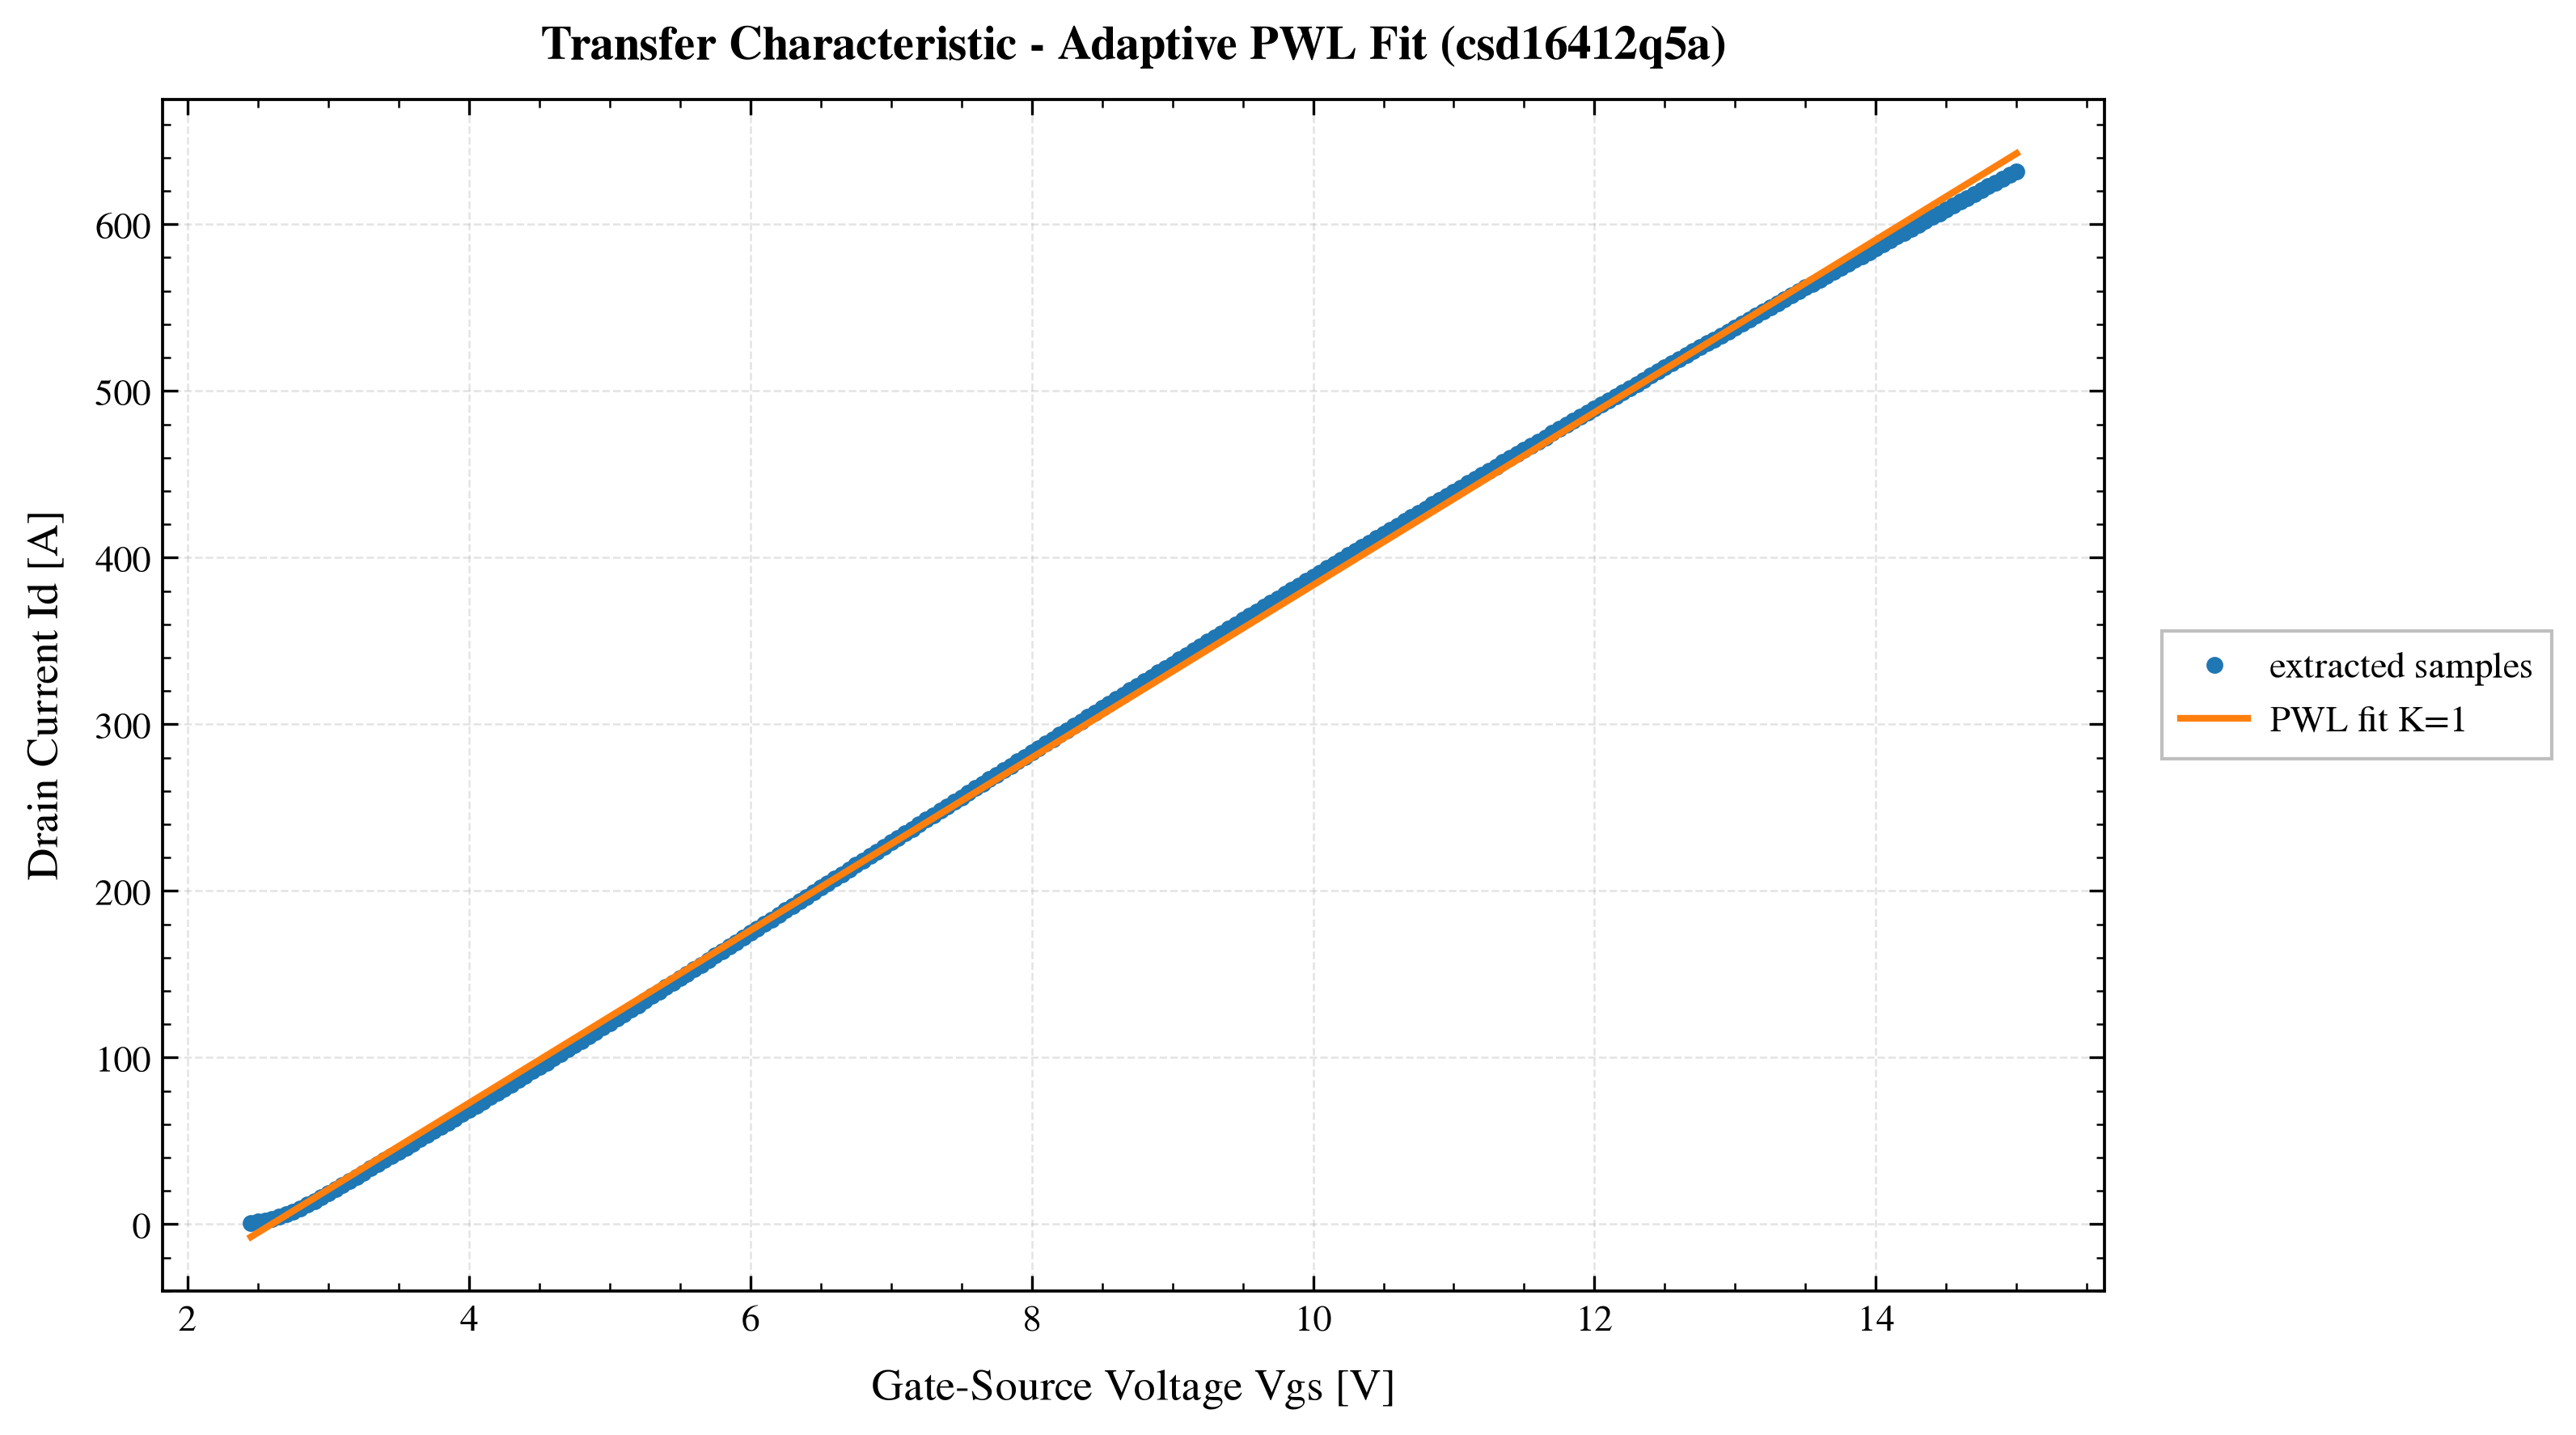

PWL K=1: RMSE=4.006, max|e|=10.64, breaks=[ 2.45 15.  ]
stop_reason : tolerance_met
relative RMSE: 0.635% of span


In [2]:
# --- Fit the transfer characteristic with adaptive PWL (M3.1) ---
from approximation.pwlf_fit import fit_adaptive

c2 = load_output(VENDOR, "curve2_transfer_characteristic")["extracted"]
vgs = np.asarray(c2["curve_vgs"])
i_d = np.asarray(c2["curve_id"])
mask = i_d > max(1e-7, 0.001 * i_d.max())     # conducting region

fit = fit_adaptive(vgs[mask], i_d[mask], rel_tolerance=0.01)
x_dense = np.linspace(vgs[mask][0], vgs[mask][-1], 400)

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
ax.plot(vgs[mask], i_d[mask], "o", ms=4, label="extracted samples")
ax.plot(x_dense, fit.evaluate(x_dense), lw=2,
        label=f"PWL fit K={fit.n_segments}")
for bp in fit.breakpoints_x[1:-1]:
    ax.axvline(bp, ls=":", color="gray", lw=1)
ax.set_xlabel("Gate-Source Voltage Vgs [V]")
ax.set_ylabel("Drain Current Id [A]")
ax.set_title(f"Transfer Characteristic - Adaptive PWL Fit ({VENDOR})")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
print(fit.summary())
print(f"stop_reason : {fit.stop_reason}")
rel = fit.rmse / (i_d[mask].max() - i_d[mask].min()) * 100
print(f"relative RMSE: {rel:.3f}% of span")

---
## 2 · Output Family — RDP Compression

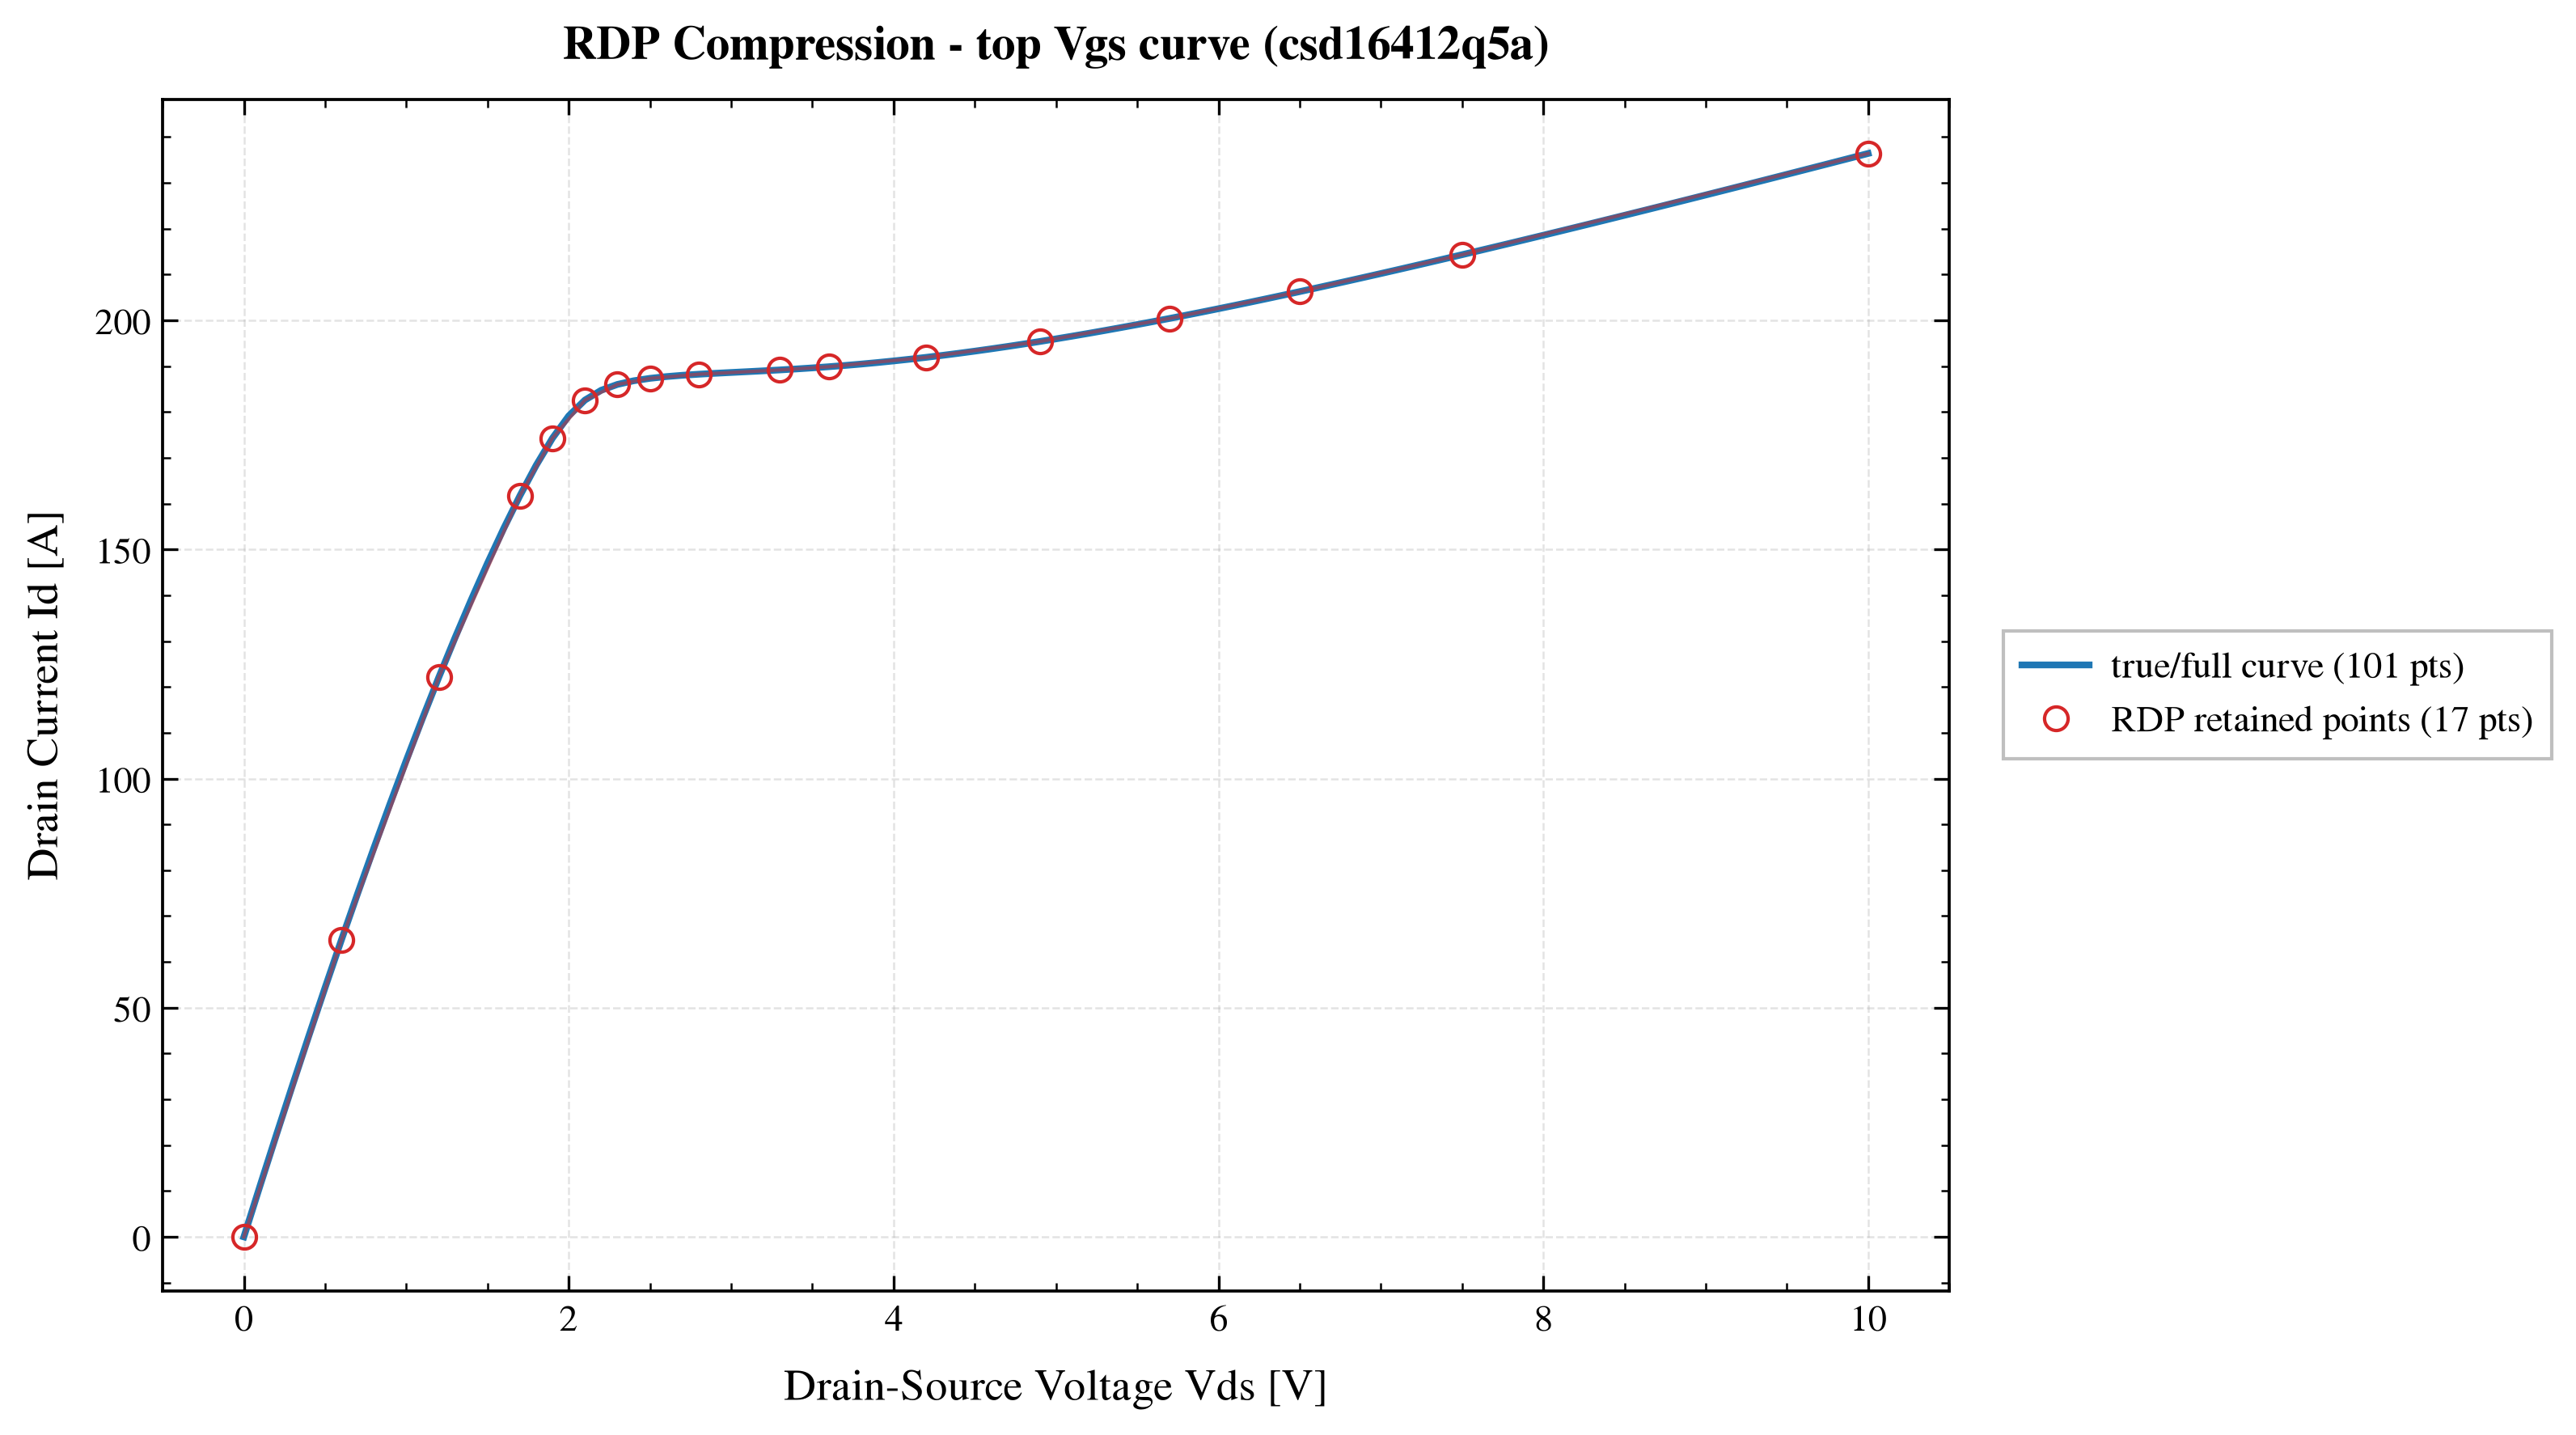

epsilon chosen : 3.625e-02
compression    : 101 -> 17 points (17%)
max deviation  : 1.115e+00 A (budget 2.364e+00 A)


In [3]:
# --- RDP compression of the output characteristics (M3.2) ---
from approximation.rdp_compress import compress_rdp, rdp_epsilon_for_max_error

c1 = load_output(VENDOR, "curve1_output_characteristics")["extracted"]
top_key = sorted(k for k in c1 if k.startswith("curve_id_vgs_"))[-1]
y = np.asarray(c1[top_key])
x = np.linspace(0, float(cfg["conditions"]["Vds_sweep_max"]), len(y))

budget = 0.01 * y.max()
eps = rdp_epsilon_for_max_error(x, y, max_error=budget)
xc, yc = compress_rdp(x, y, epsilon=eps)

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
ax.plot(x, y, lw=2, color="tab:blue",
        label=f"true/full curve ({len(x)} pts)")
ax.plot(xc, yc, "o", ms=7, mfc="none", color="tab:red", lw=1,
        label=f"RDP retained points ({len(xc)} pts)")
# chord reconstruction through retained points (what SPICE would use)
ax.plot(xc, yc, "-", lw=1, color="tab:red", alpha=0.5)
ax.set_xlabel("Drain-Source Voltage Vds [V]")
ax.set_ylabel("Drain Current Id [A]")
ax.set_title(f"RDP Compression - top Vgs curve ({VENDOR})")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
interp_err = np.max(np.abs(np.interp(x, xc, yc) - y))
print(f"epsilon chosen : {eps:.3e}")
print(f"compression    : {len(x)} -> {len(xc)} points "
      f"({100*len(xc)/len(x):.0f}%)")
print(f"max deviation  : {interp_err:.3e} A (budget {budget:.3e} A)")

---
## 3 · Charge Integration — Qoss(V) & PWL Table

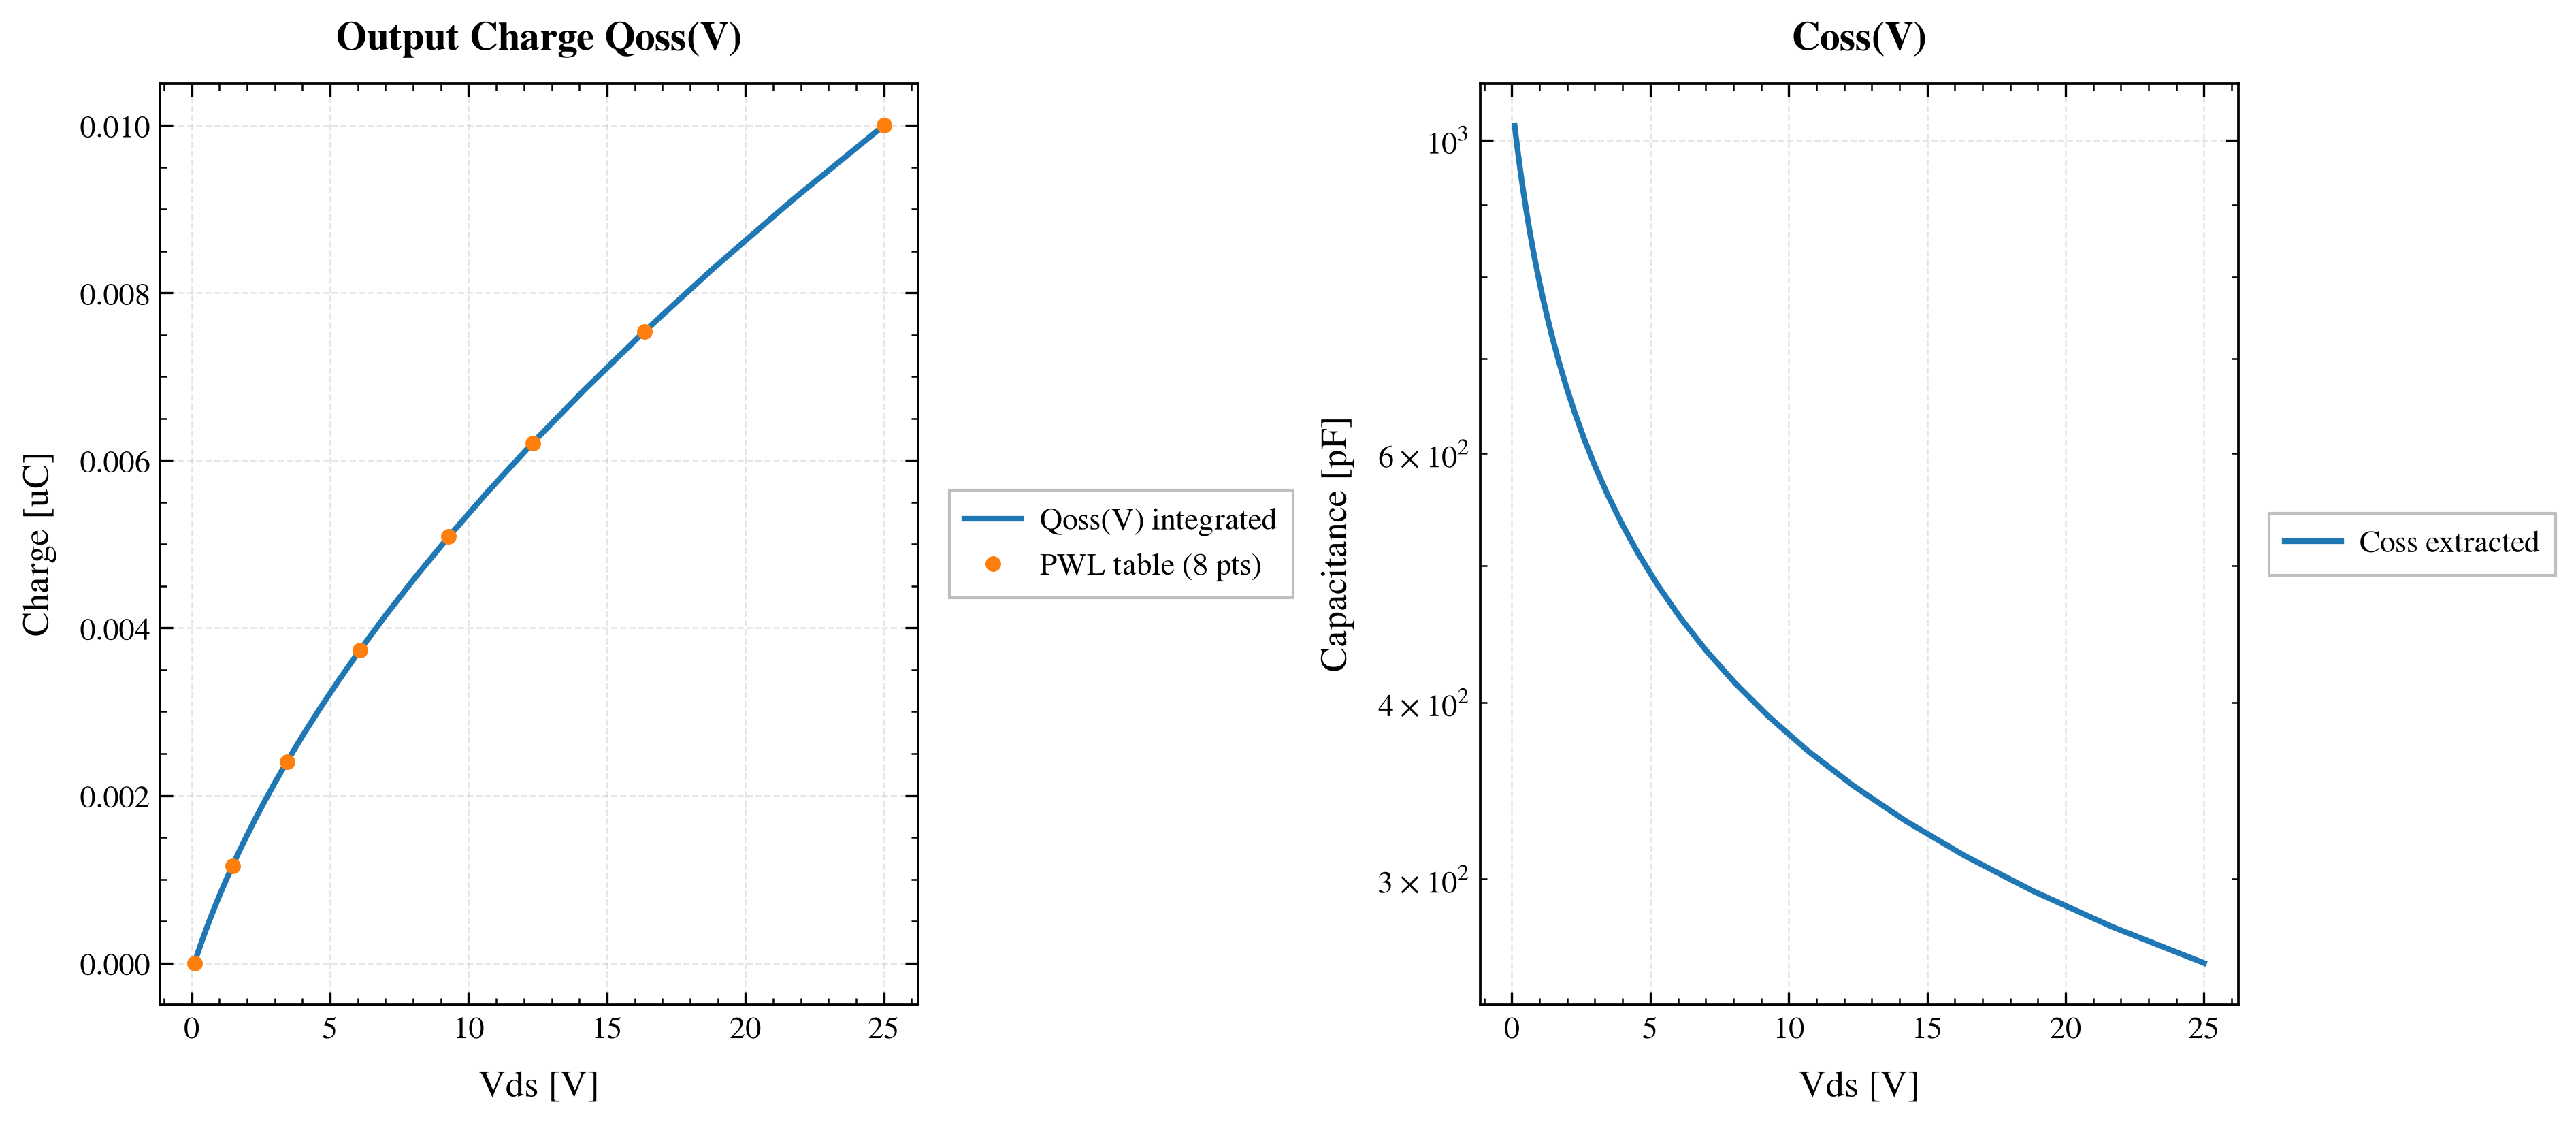

Qoss(25V)     : 0.0100 uC
Eoss(25V)     : 0.1020 uJ
C_eq(charge)   : 0.4000 nF
C_eq(energy)   : 0.3264 nF
PWL table      : 8 pts, max err 0.0496 nC


In [4]:
# --- Charge model: Qoss(V), equivalent caps, PWL table (M3.3) ---
from approximation.charge_model import (
    integrate_charge, pwl_charge_segments, synthesize_charge_source)

cond = cfg["conditions"]
cap_ref = float(cond.get("Cap_ref_Vds", 25.0))

# Re-extract Coss at full resolution for the charge table
from parser.netlist import resolve_pin_connections
from simulation.testbenches.capacitance import CapacitanceTestbench
lib = Path(cfg["library"]).resolve()
roles = resolve_pin_connections(lib, cfg["subcircuit"],
    pin_order_semantic=cfg.get("pins", {}).get("pin_order_semantic"))
_, coss, _ = CapacitanceTestbench(f_meas=cond.get("F_meas")).run(
    lib, cfg["subcircuit"], vds_min=cond["Vds_cap_min"],
    vds_max=cond["Vds_cap_max"], points=cond["Cap_points"],
    pin_roles=roles)

cm = integrate_charge(np.asarray(coss.x_data), np.asarray(coss.y_data),
                      v_ref=cap_ref)
table = pwl_charge_segments(coss.x_data, coss.y_data)

fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.4), layout="constrained")
axs[0].plot(cm.v, cm.q * 1e6, lw=2, label="Qoss(V) integrated")
axs[0].plot(table.v_breaks, np.asarray(table.q_values) * 1e6, "o",
            label=f"PWL table ({table.n_points} pts)")
axs[0].set_xlabel("Vds [V]"); axs[0].set_ylabel("Charge [uC]")
axs[0].set_title("Output Charge Qoss(V)")
axs[0].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))

axs[1].semilogy(cm.v, cm.c * 1e12, lw=2, label="Coss extracted")
axs[1].set_xlabel("Vds [V]"); axs[1].set_ylabel("Capacitance [pF]")
axs[1].set_title("Coss(V)")
axs[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

print(f"Qoss({cap_ref:g}V)     : {cm.q[-1]*1e6:.4f} uC")
print(f"Eoss({cap_ref:g}V)     : {cm.e[-1]*1e6:.4f} uJ")
print(f"C_eq(charge)   : {cm.c_eq_charge*1e9:.4f} nF")
print(f"C_eq(energy)   : {cm.c_eq_energy*1e9:.4f} nF")
print(f"PWL table      : {table.n_points} pts, "
      f"max err {table.max_abs_error_c*1e9:.4f} nC")

---
## 4 · Knee Smoothing — Hard PWL vs C¹ tanh

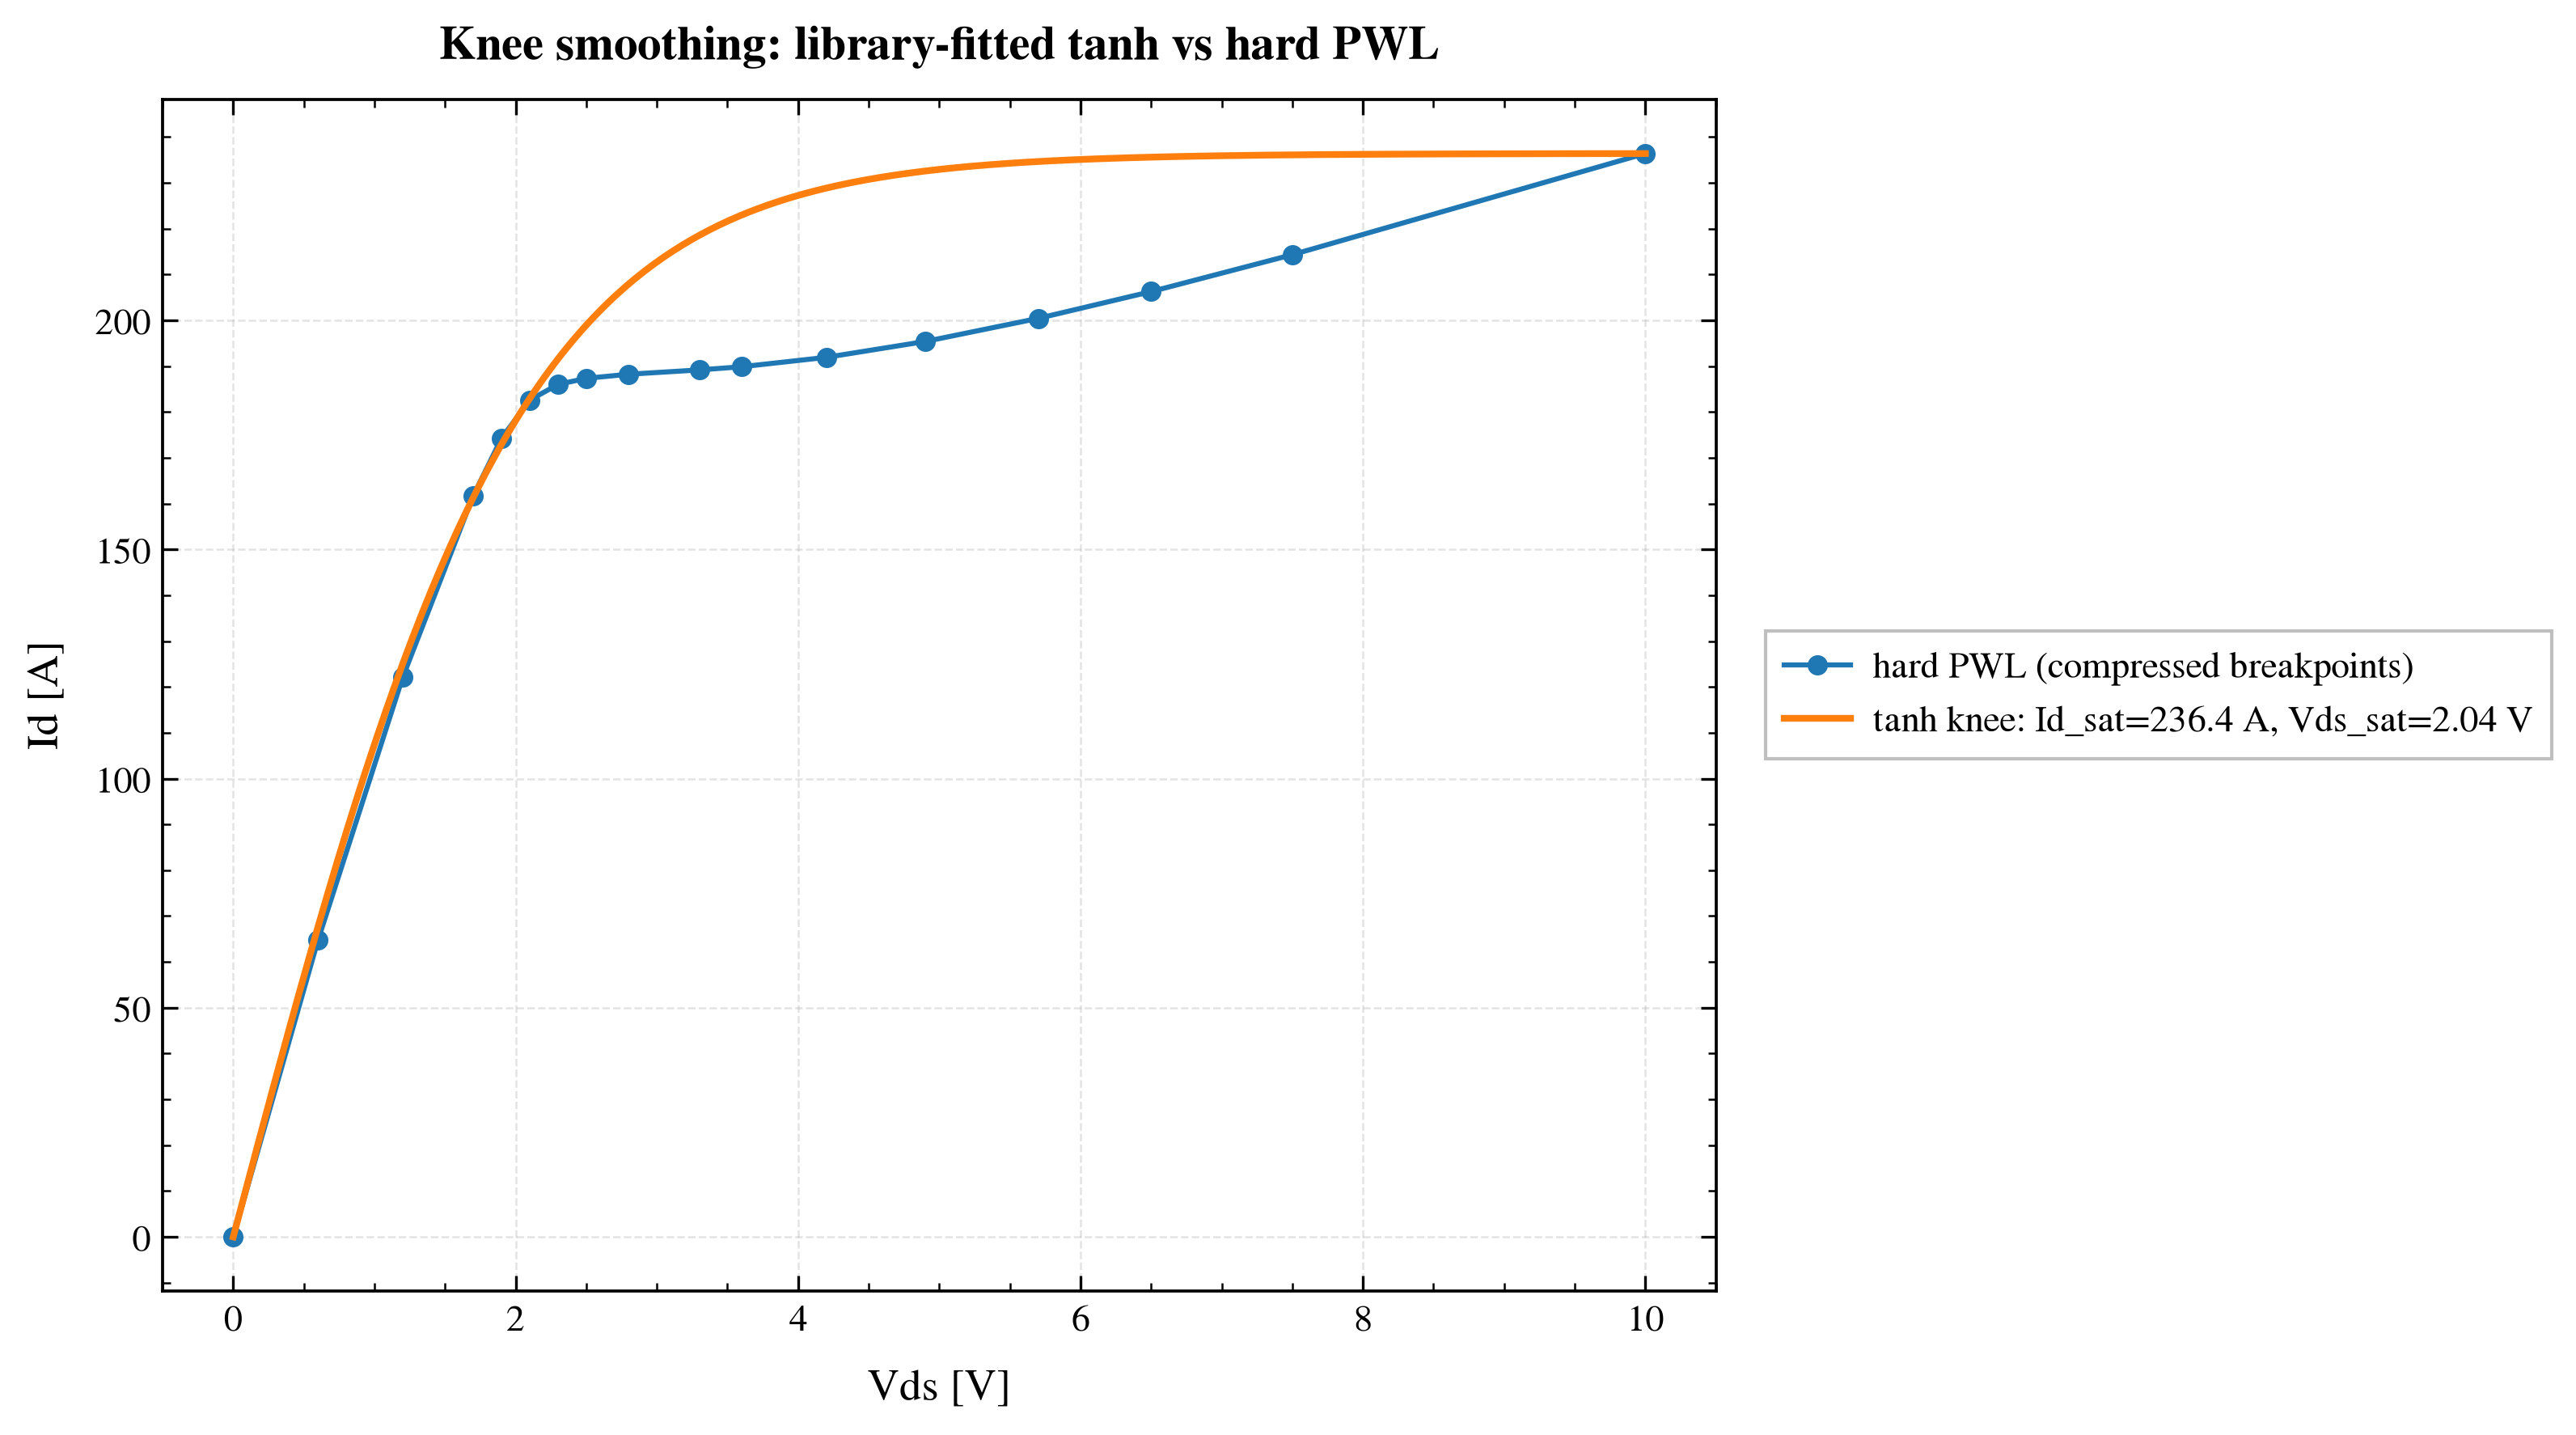

max |tanh - PWL| : 37.38 A (15.8% of Id_sat) - localized at the knee


In [5]:
# --- C1 knee smoothing (M3.4): fit tanh knee to the compressed curve ---
from approximation.smoother import tanh_saturation, fit_tanh_knee

vds_pwl, ids_pwl = xc, yc          # RDP output from section 2 (data only)
knee = fit_tanh_knee(vds_pwl, ids_pwl)   # library owns the derivation

vds_dense = np.linspace(vds_pwl[0], vds_pwl[-1], 300)
ids_smooth = tanh_saturation(vds_dense,
                             v_ds_sat=knee.v_ds_sat, gm=knee.gm)

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
ax.plot(vds_pwl, ids_pwl, "o-", ms=5, lw=1.5,
        label="hard PWL (compressed breakpoints)")
ax.plot(vds_dense, ids_smooth, lw=2,
        label=f"tanh knee: Id_sat={knee.id_sat:.1f} A, "
              f"Vds_sat={knee.v_ds_sat:.2f} V")
ax.set_xlabel("Vds [V]"); ax.set_ylabel("Id [A]")
ax.set_title("Knee smoothing: library-fitted tanh vs hard PWL")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
print(f"max |tanh - PWL| : {knee.max_abs_deviation_a:.2f} A "
      f"({100*knee.max_abs_deviation_a/knee.id_sat:.1f}% of Id_sat) - "
      f"localized at the knee")

---
## 5 · Tier-2 Synthesis & Validation vs Golden

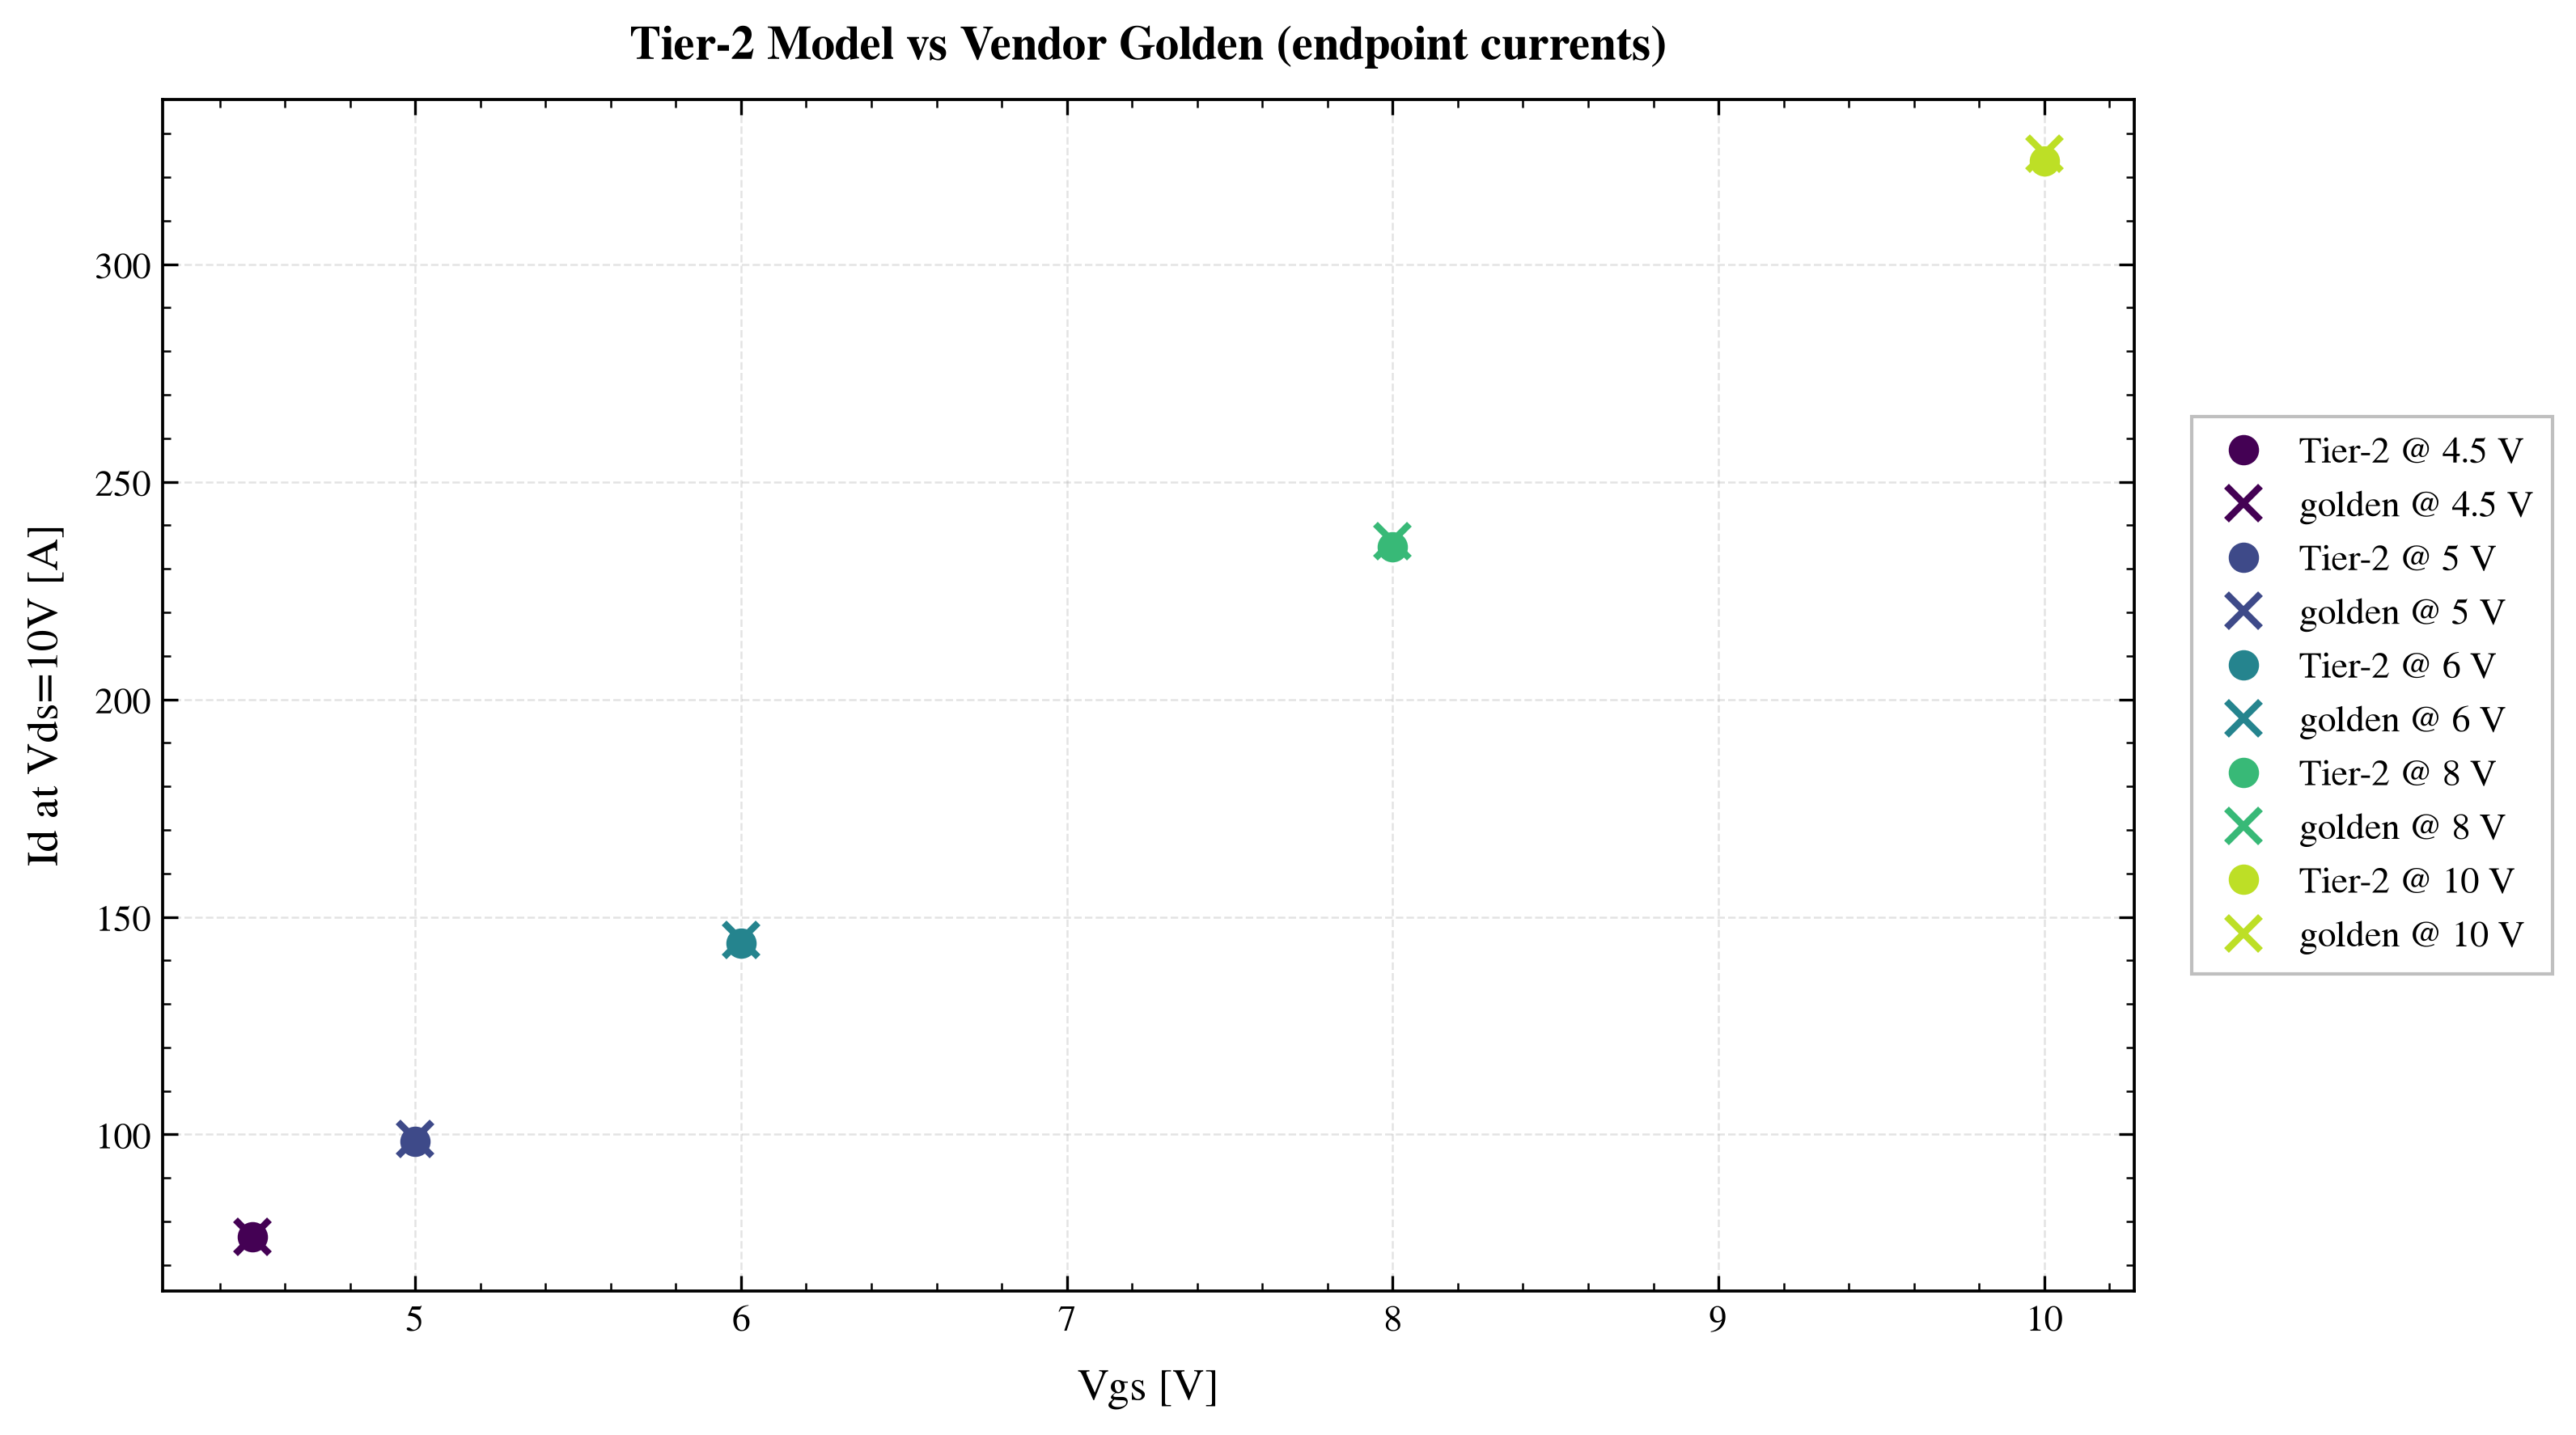

   Vgs     Golden     Tier-2    Error
   4.5      76.50      76.45    0.07%
   5.0      98.95      98.44    0.51%
   6.0     144.73     143.97    0.52%
   8.0     236.39     235.14    0.53%
  10.0     325.46     323.79    0.51%

Worst endpoint error: 0.53%  (target < 5%)
NOTE: endpoint errors are small; the full-sweep rel-RMSE column additionally exposes knee-shape mismatch for lower-Vgs curves - a known Tier-2 single-knee limitation.


In [6]:
# --- Tier-2 synthesis + validation vs golden (M3.5/3.6) ---
from pipeline.fitting import fit_pwl_model, compare_tier2_vs_golden
from PySpice.Spice.Netlist import Circuit

lib = fit_pwl_model(VENDOR)
rows, worst_pct = compare_tier2_vs_golden(VENDOR, lib)

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
colors = plt.cm.viridis(np.linspace(0, 0.9, len(rows)))
for (vgs_val, golden, t2, _rel), col in zip(rows, colors):
    # tie-line: its length IS the model error at this drive level
    ax.plot([vgs_val, vgs_val], [golden, t2], "-", color=col,
            alpha=0.5, lw=1)
    ax.plot(vgs_val, t2, "o", color=col, ms=8,
            label=f"Tier-2 @ {vgs_val:g} V")
    ax.plot(vgs_val, golden, "x", color=col, ms=10, mew=2,
            label=f"golden @ {vgs_val:g} V")
ax.set_xlabel("Vgs [V]"); ax.set_ylabel("Id at Vds=10V [A]")
ax.set_title("Tier-2 Model vs Vendor Golden (endpoint currents)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

print(f"{'Vgs':>6} {'Golden':>10} {'Tier-2':>10} {'Error':>8}")
worst = 0.0
for v, g, t2, rel in rows:
    print(f"{v:6.1f} {g:10.2f} {t2:10.2f} {rel:7.2f}%")
    worst = max(worst, rel)
print(f"\nWorst endpoint error: {worst:.2f}%  (target < 5%)")
print("NOTE: endpoint errors are small; the full-sweep rel-RMSE column additionally exposes knee-shape mismatch for lower-Vgs curves - a known Tier-2 single-knee limitation.")

---
# Model Evaluation — Golden vs Tier-2 Comparison Metrics

Unified comparison framework (`metrics/compare.py`): per-curve error
normals, global scorecard, and industry-standard comparison figures.

**Metrics:** RMSE, L∞ max error, relative RMSE (% of span), MAPE, R²

**Plots:** overlay small-multiples · signed residual traces ·
scorecard bars with target line · parity scatter with 45° line

In [7]:
# --- Build golden-vs-Tier-2 pairs on the full Vds grid (per Vgs) ---
# Library owns the simulation loop; this cell only consumes rows.
import pandas as pd
from metrics.compare import (
    build_report, report_to_rows, plot_overlays, plot_residuals,
    plot_scorecard_bars, plot_parity)
from pipeline.fitting import compare_tier2_vs_golden_full

rows_full = compare_tier2_vs_golden_full(VENDOR)

pairs = []
for vgs_val, vds_arr, y_golden, y_t2 in rows_full:
    pairs.append((f"Vgs = {vgs_val:g} V", np.asarray(vds_arr),
                  np.asarray(y_golden), np.asarray(y_t2)))

report = build_report(pairs, target_rel_rmse_pct=5.0)
df_report = pd.DataFrame(report_to_rows(report))
print(df_report.to_string(index=False))
print()
print(report.summary_line())

      curve  points      rmse  rel_rmse_pct   max_err  max_rel_pct  mape_pct  r_squared  pass
Vgs = 4.5 V      41 10.936533        14.295 24.250561       31.698    17.727   0.406212 False
  Vgs = 5 V      41 13.027293        13.166 28.903544       29.211    16.378   0.528232 False
  Vgs = 6 V      41 16.493593        11.396 32.733875       22.618    14.482   0.690875 False
  Vgs = 8 V      41 19.887546         8.413 30.682803       12.980    10.242   0.866158 False
 Vgs = 10 V      41 22.483996         6.908 38.496468       11.828     7.193   0.924497 False

0/5 curves within 5% rel-RMSE target; worst = Vgs = 4.5 V (14.30%)


---
## Overlay Small-Multiples

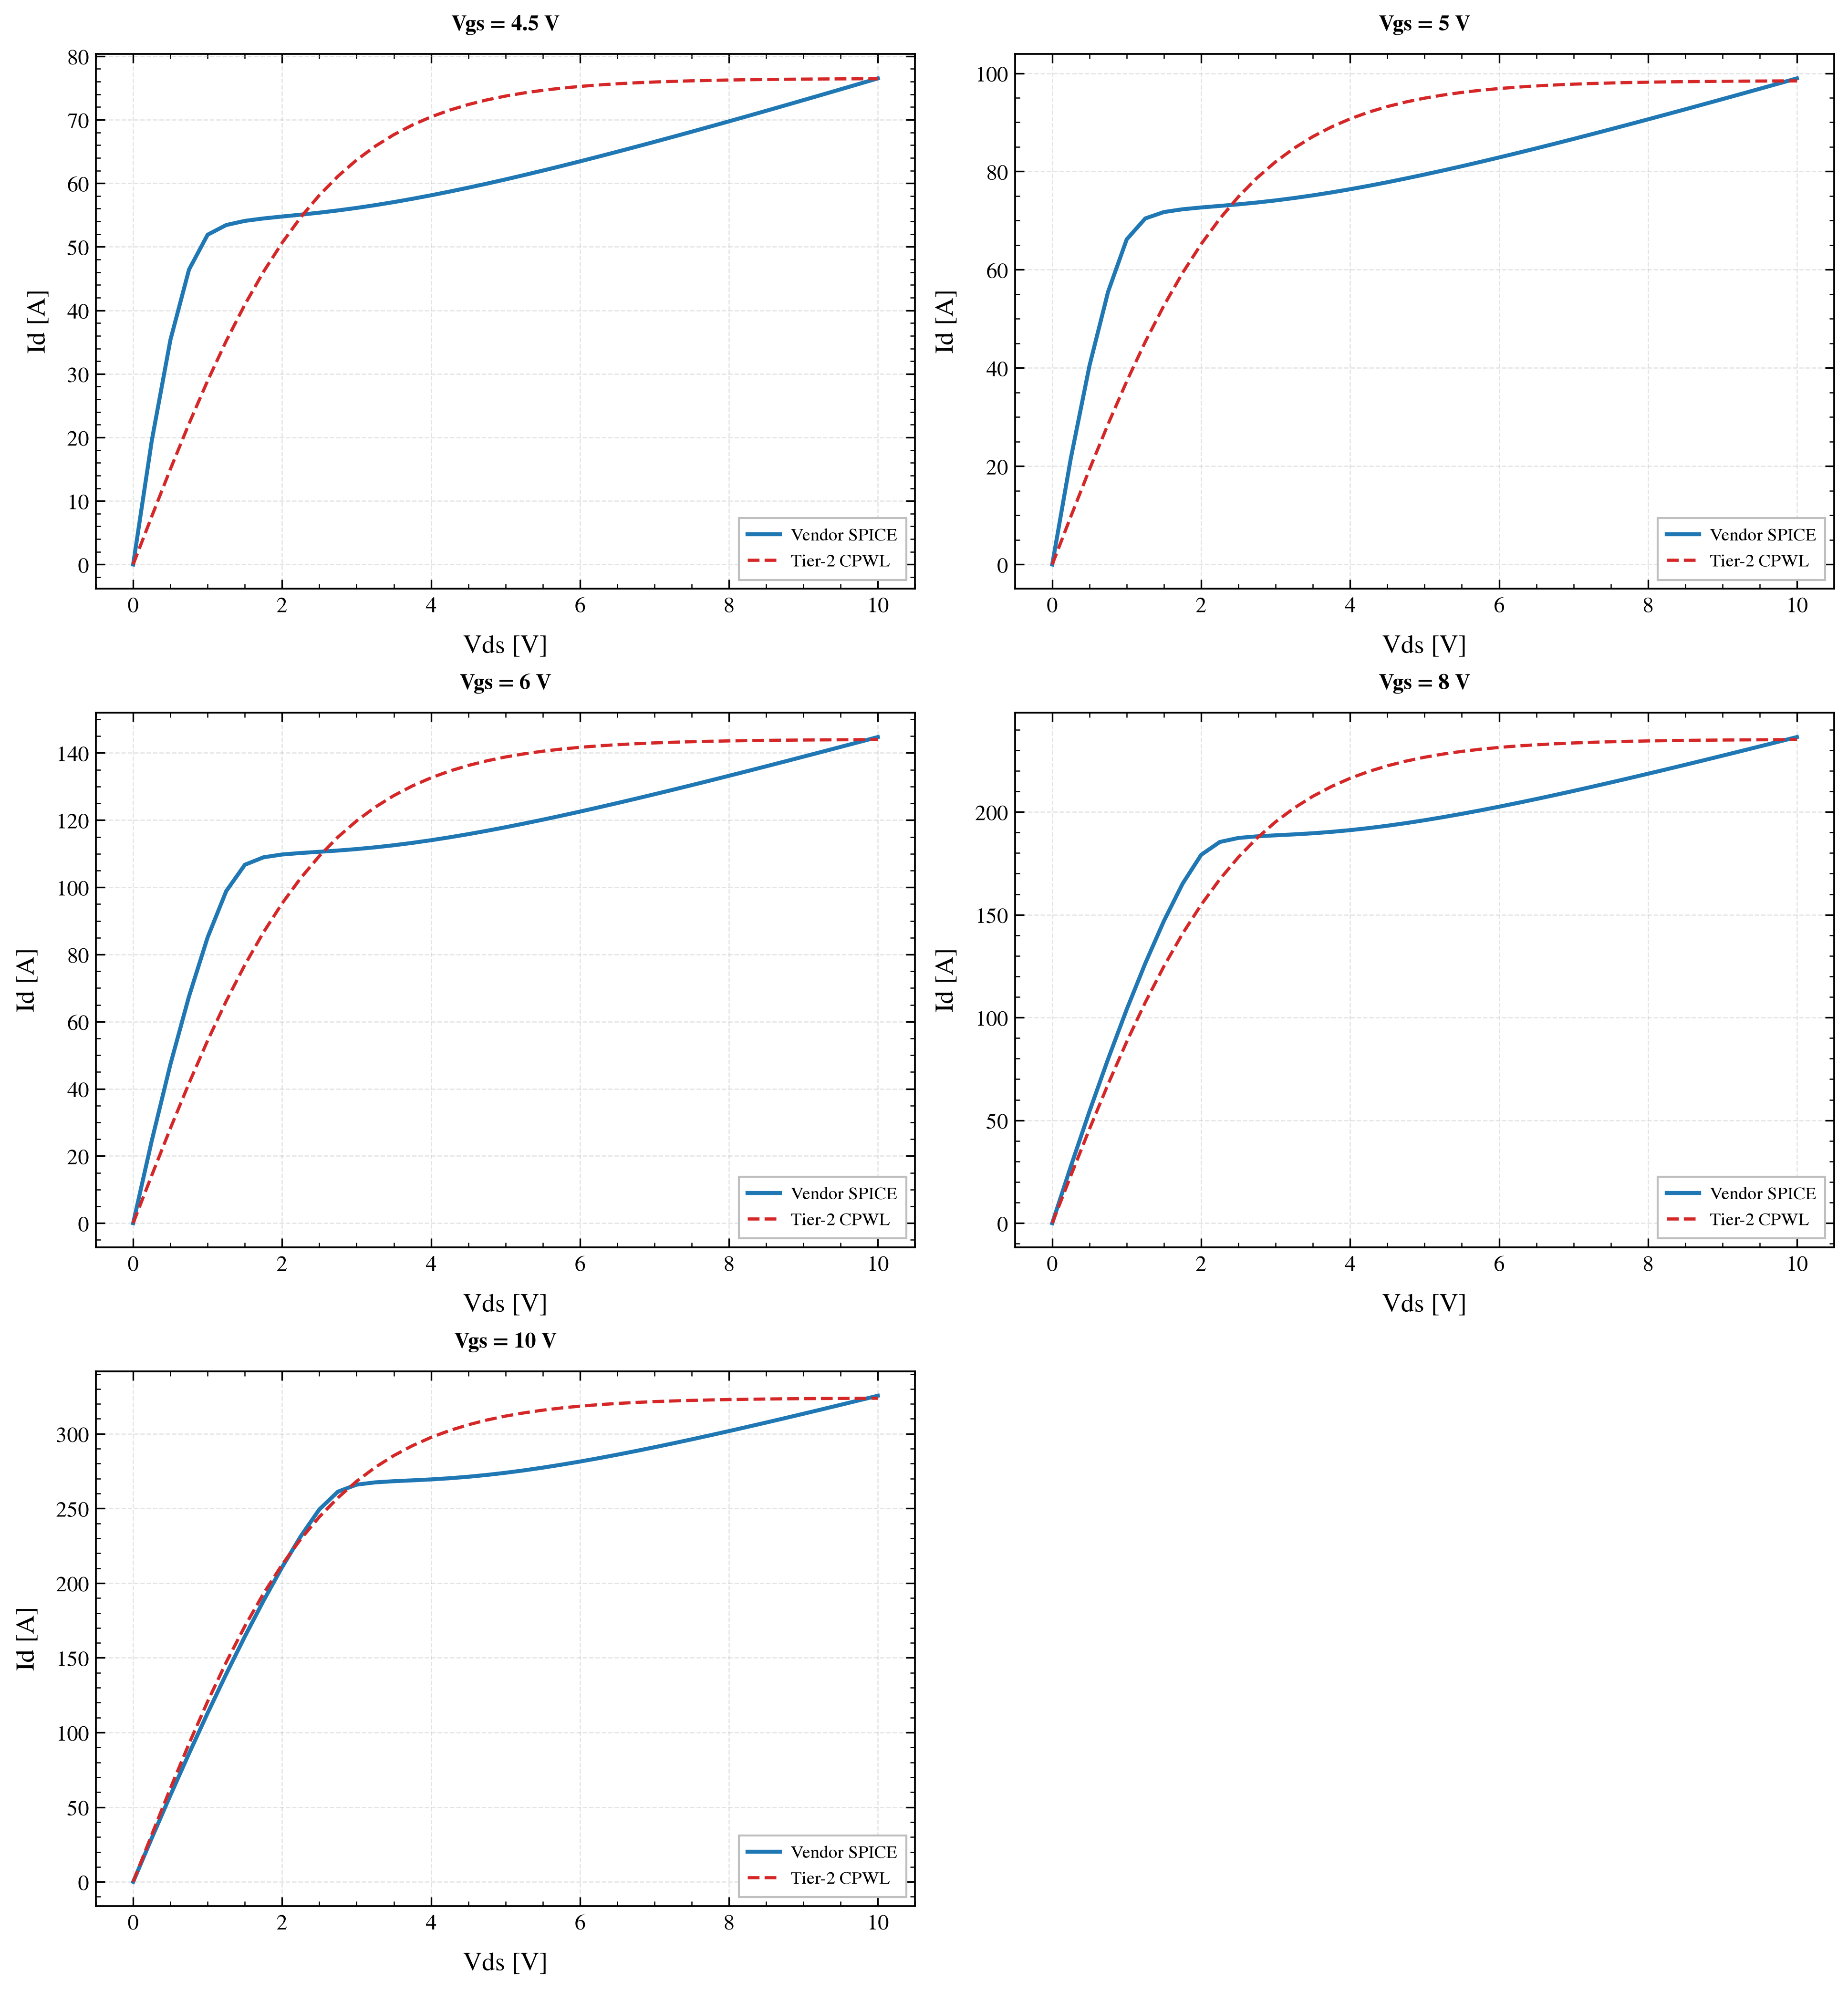

In [8]:
# Comparison plot 1: overlay small-multiples (golden vs Tier-2 per curve)
fig_ov = plot_overlays(pairs, cand_label="Tier-2 CPWL",
                       gold_label="Vendor SPICE")
plt.show()

---
## Signed Residual Traces

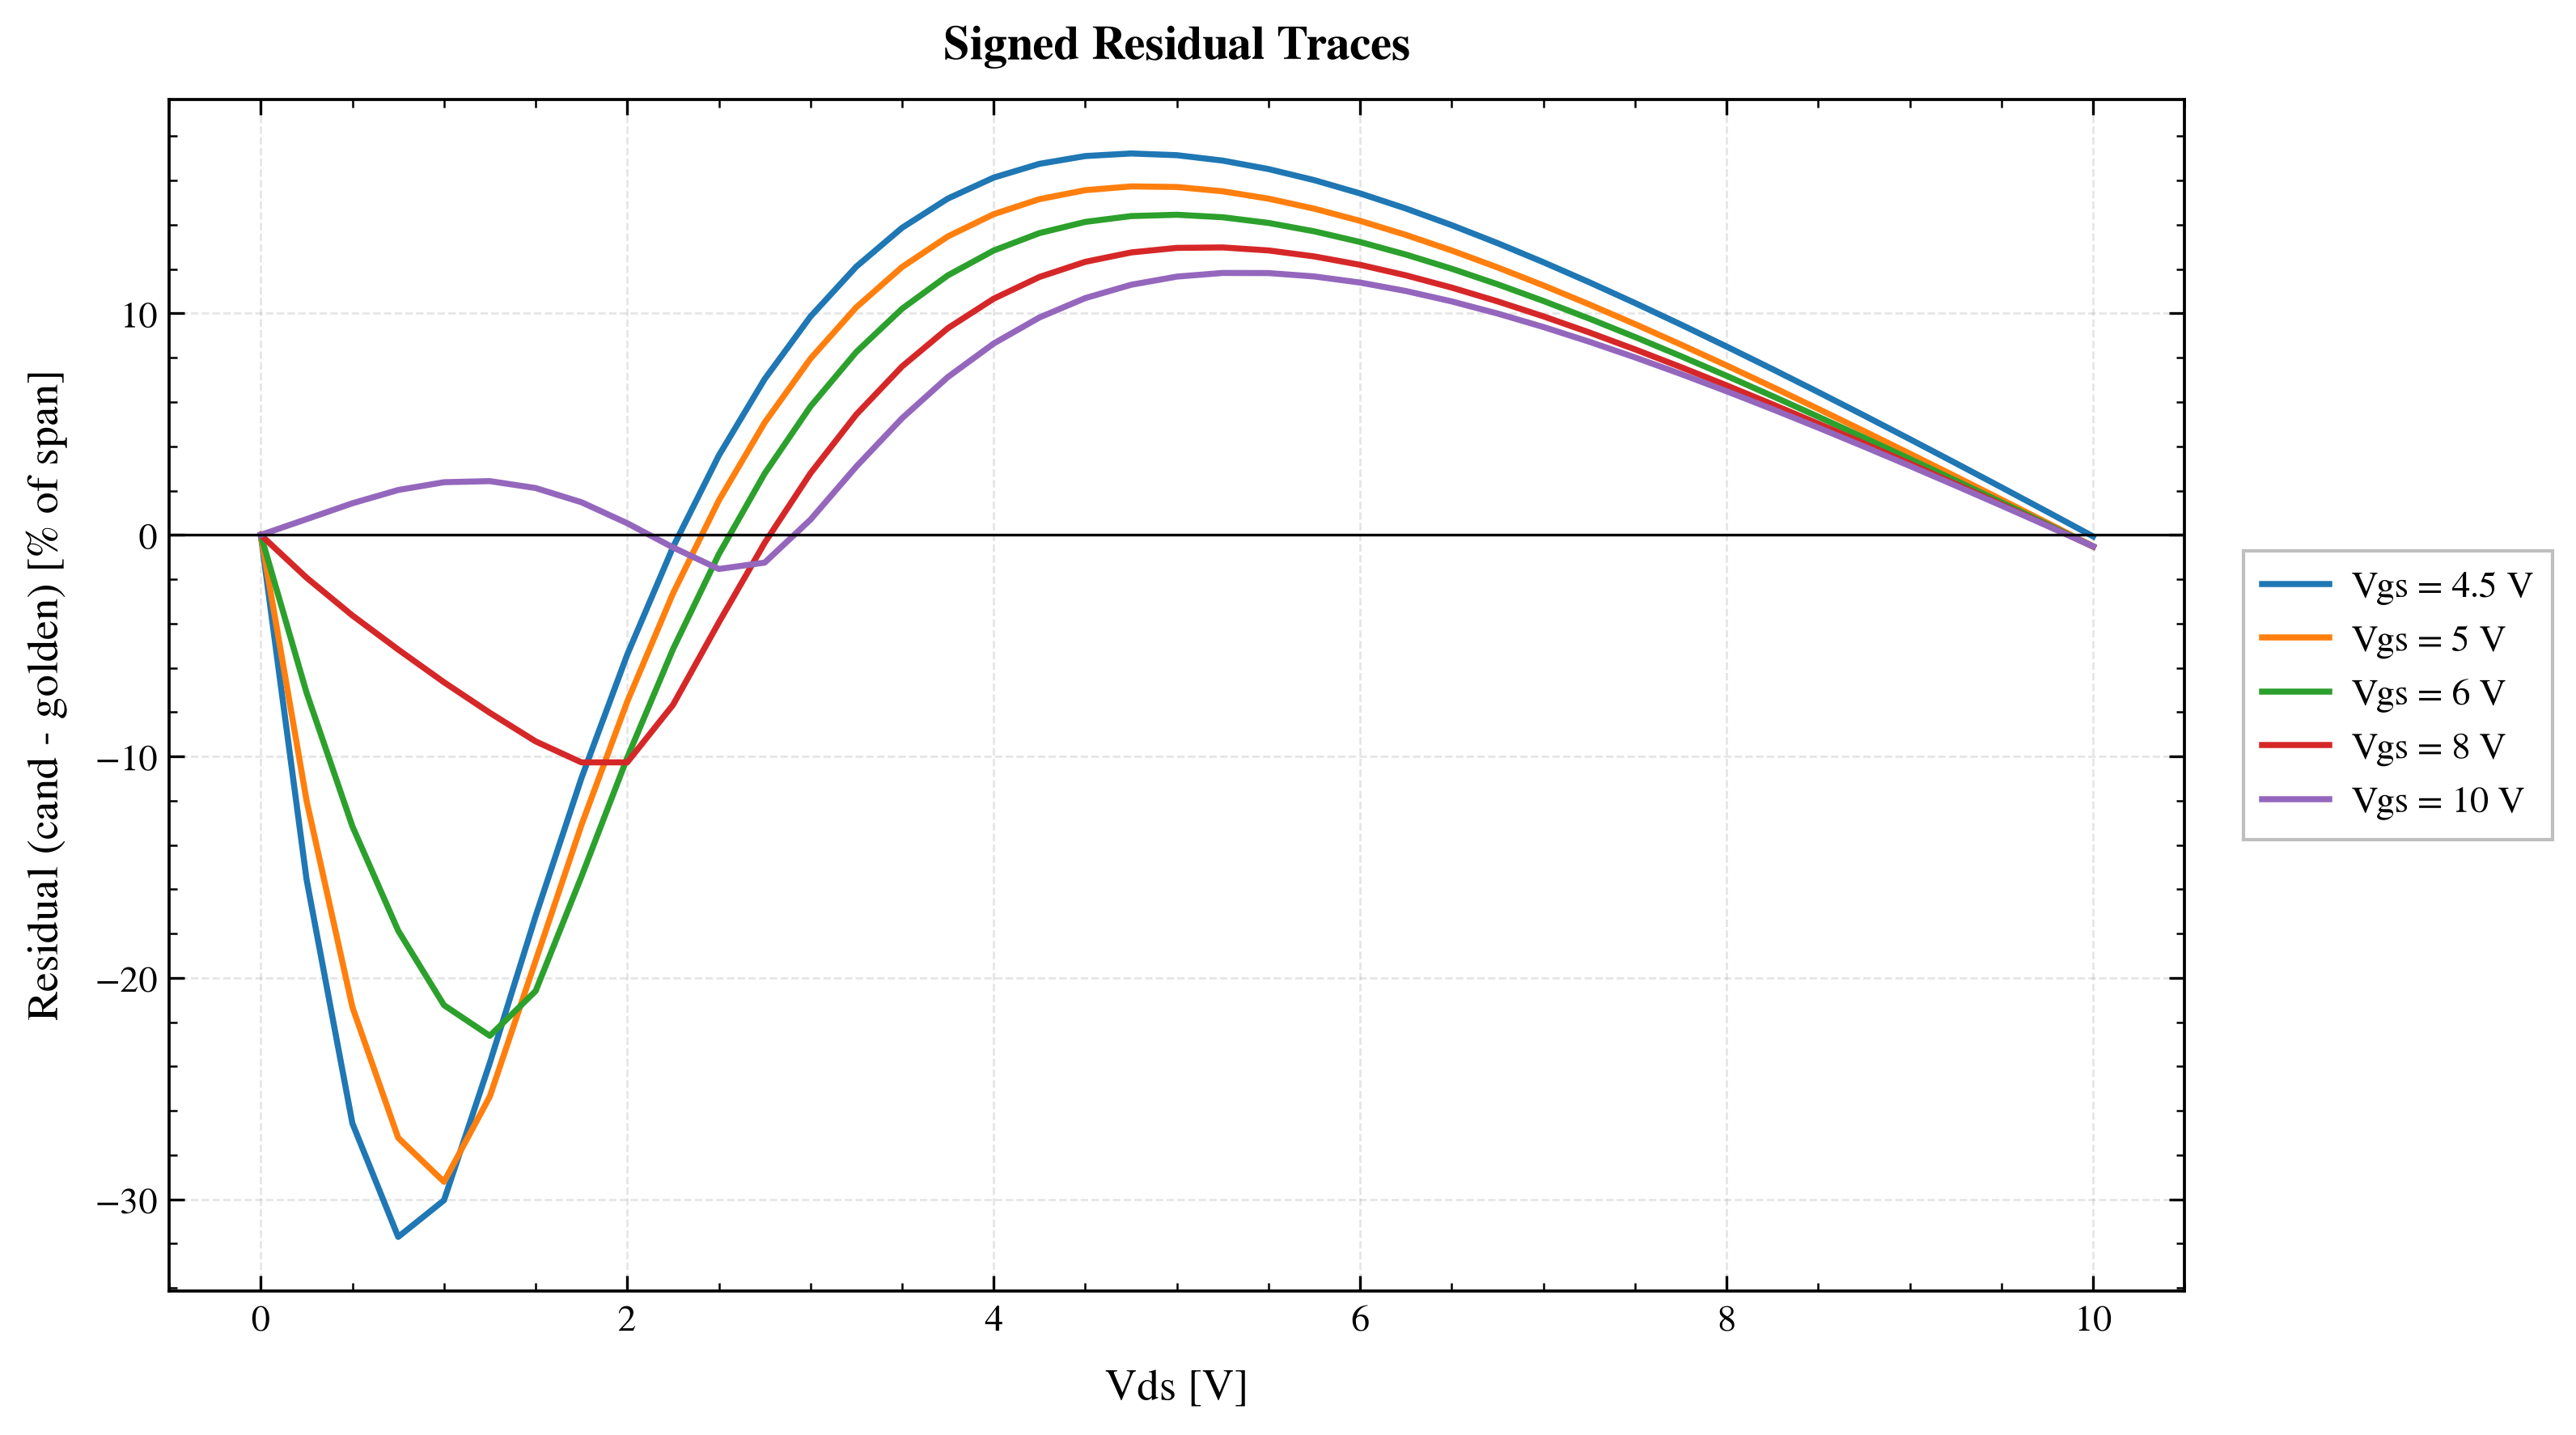

In [9]:
# Comparison plot 2: signed residual traces (% of span)
fig_res = plot_residuals(pairs, normalize_to="span")
plt.show()

---
## Fidelity Scorecard

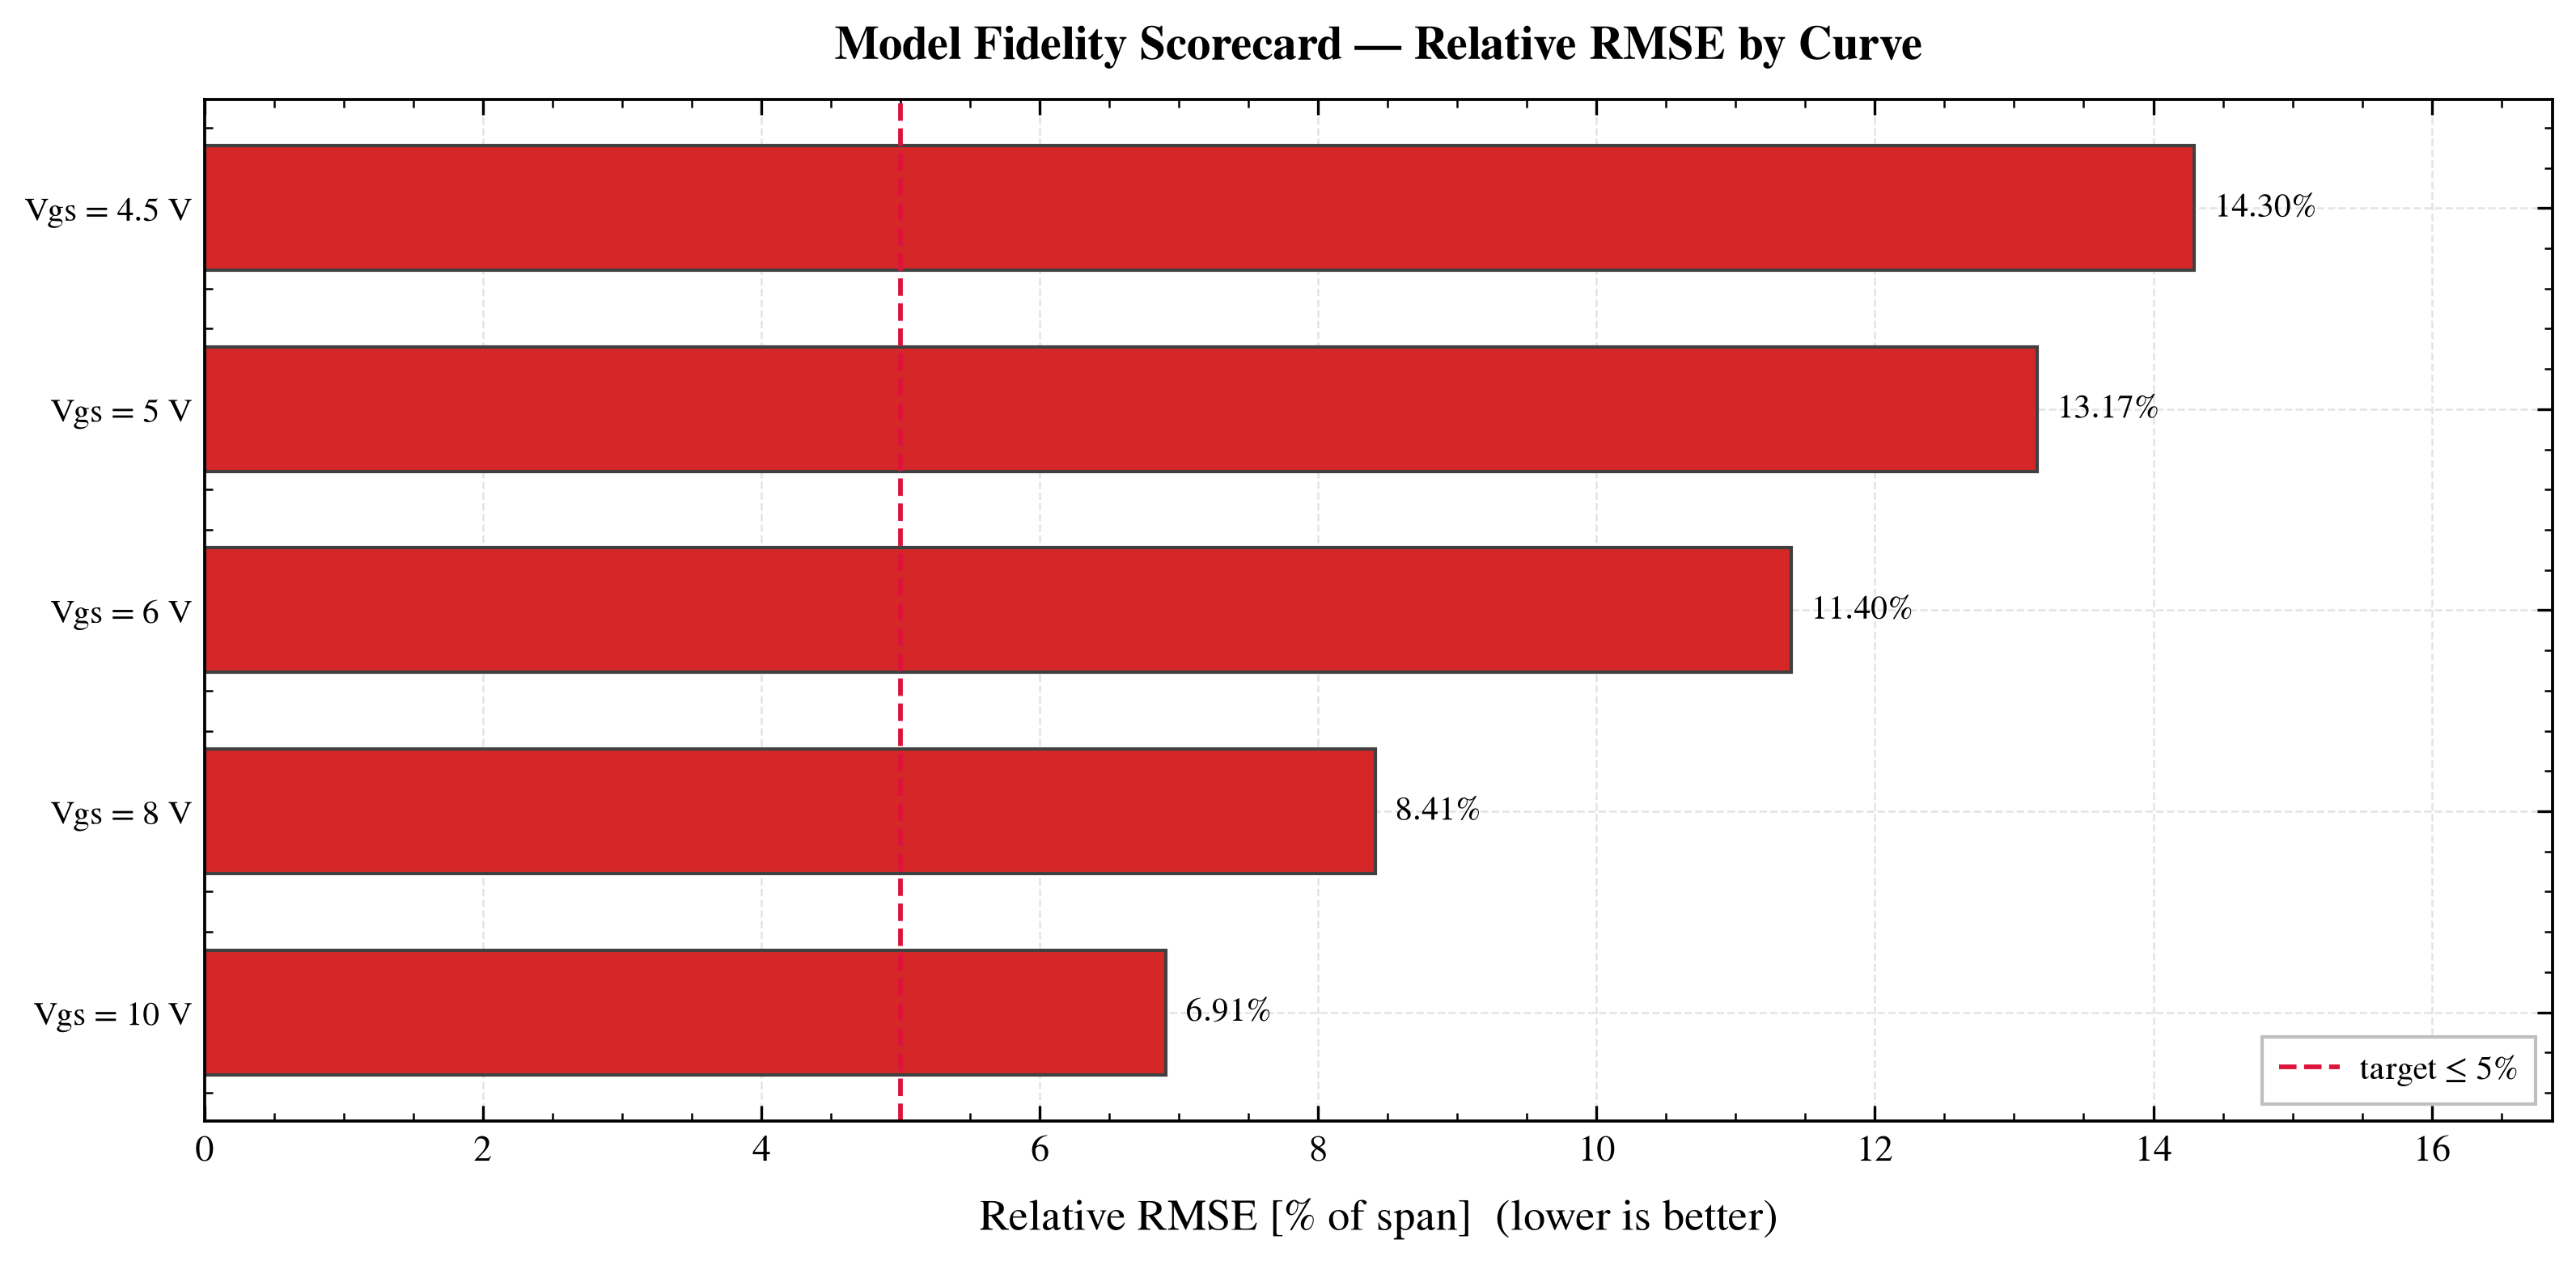

,curve,points,rmse,rel_rmse_pct,max_err,max_rel_pct,mape_pct,r_squared,pass
0,Vgs = 4.5 V,41,10.936533,14.295000,24.250561,31.698000,17.727000,0.406212,False
1,Vgs = 5 V,41,13.027293,13.166000,28.903544,29.211000,16.378000,0.528232,False
2,Vgs = 6 V,41,16.493593,11.396000,32.733875,22.618000,14.482000,0.690875,False
3,Vgs = 8 V,41,19.887546,8.413000,30.682803,12.980000,10.242000,0.866158,False
4,Vgs = 10 V,41,22.483996,6.908000,38.496468,11.828000,7.193000,0.924497,False


In [10]:
# Comparison plot 3: fidelity scorecard bars with target line
fig_score = plot_scorecard_bars(report)
plt.show()

display(df_report.style.background_gradient(
    subset=["rel_rmse_pct"], cmap="RdYlGn_r", vmin=0, vmax=5))

---
## Parity Plot

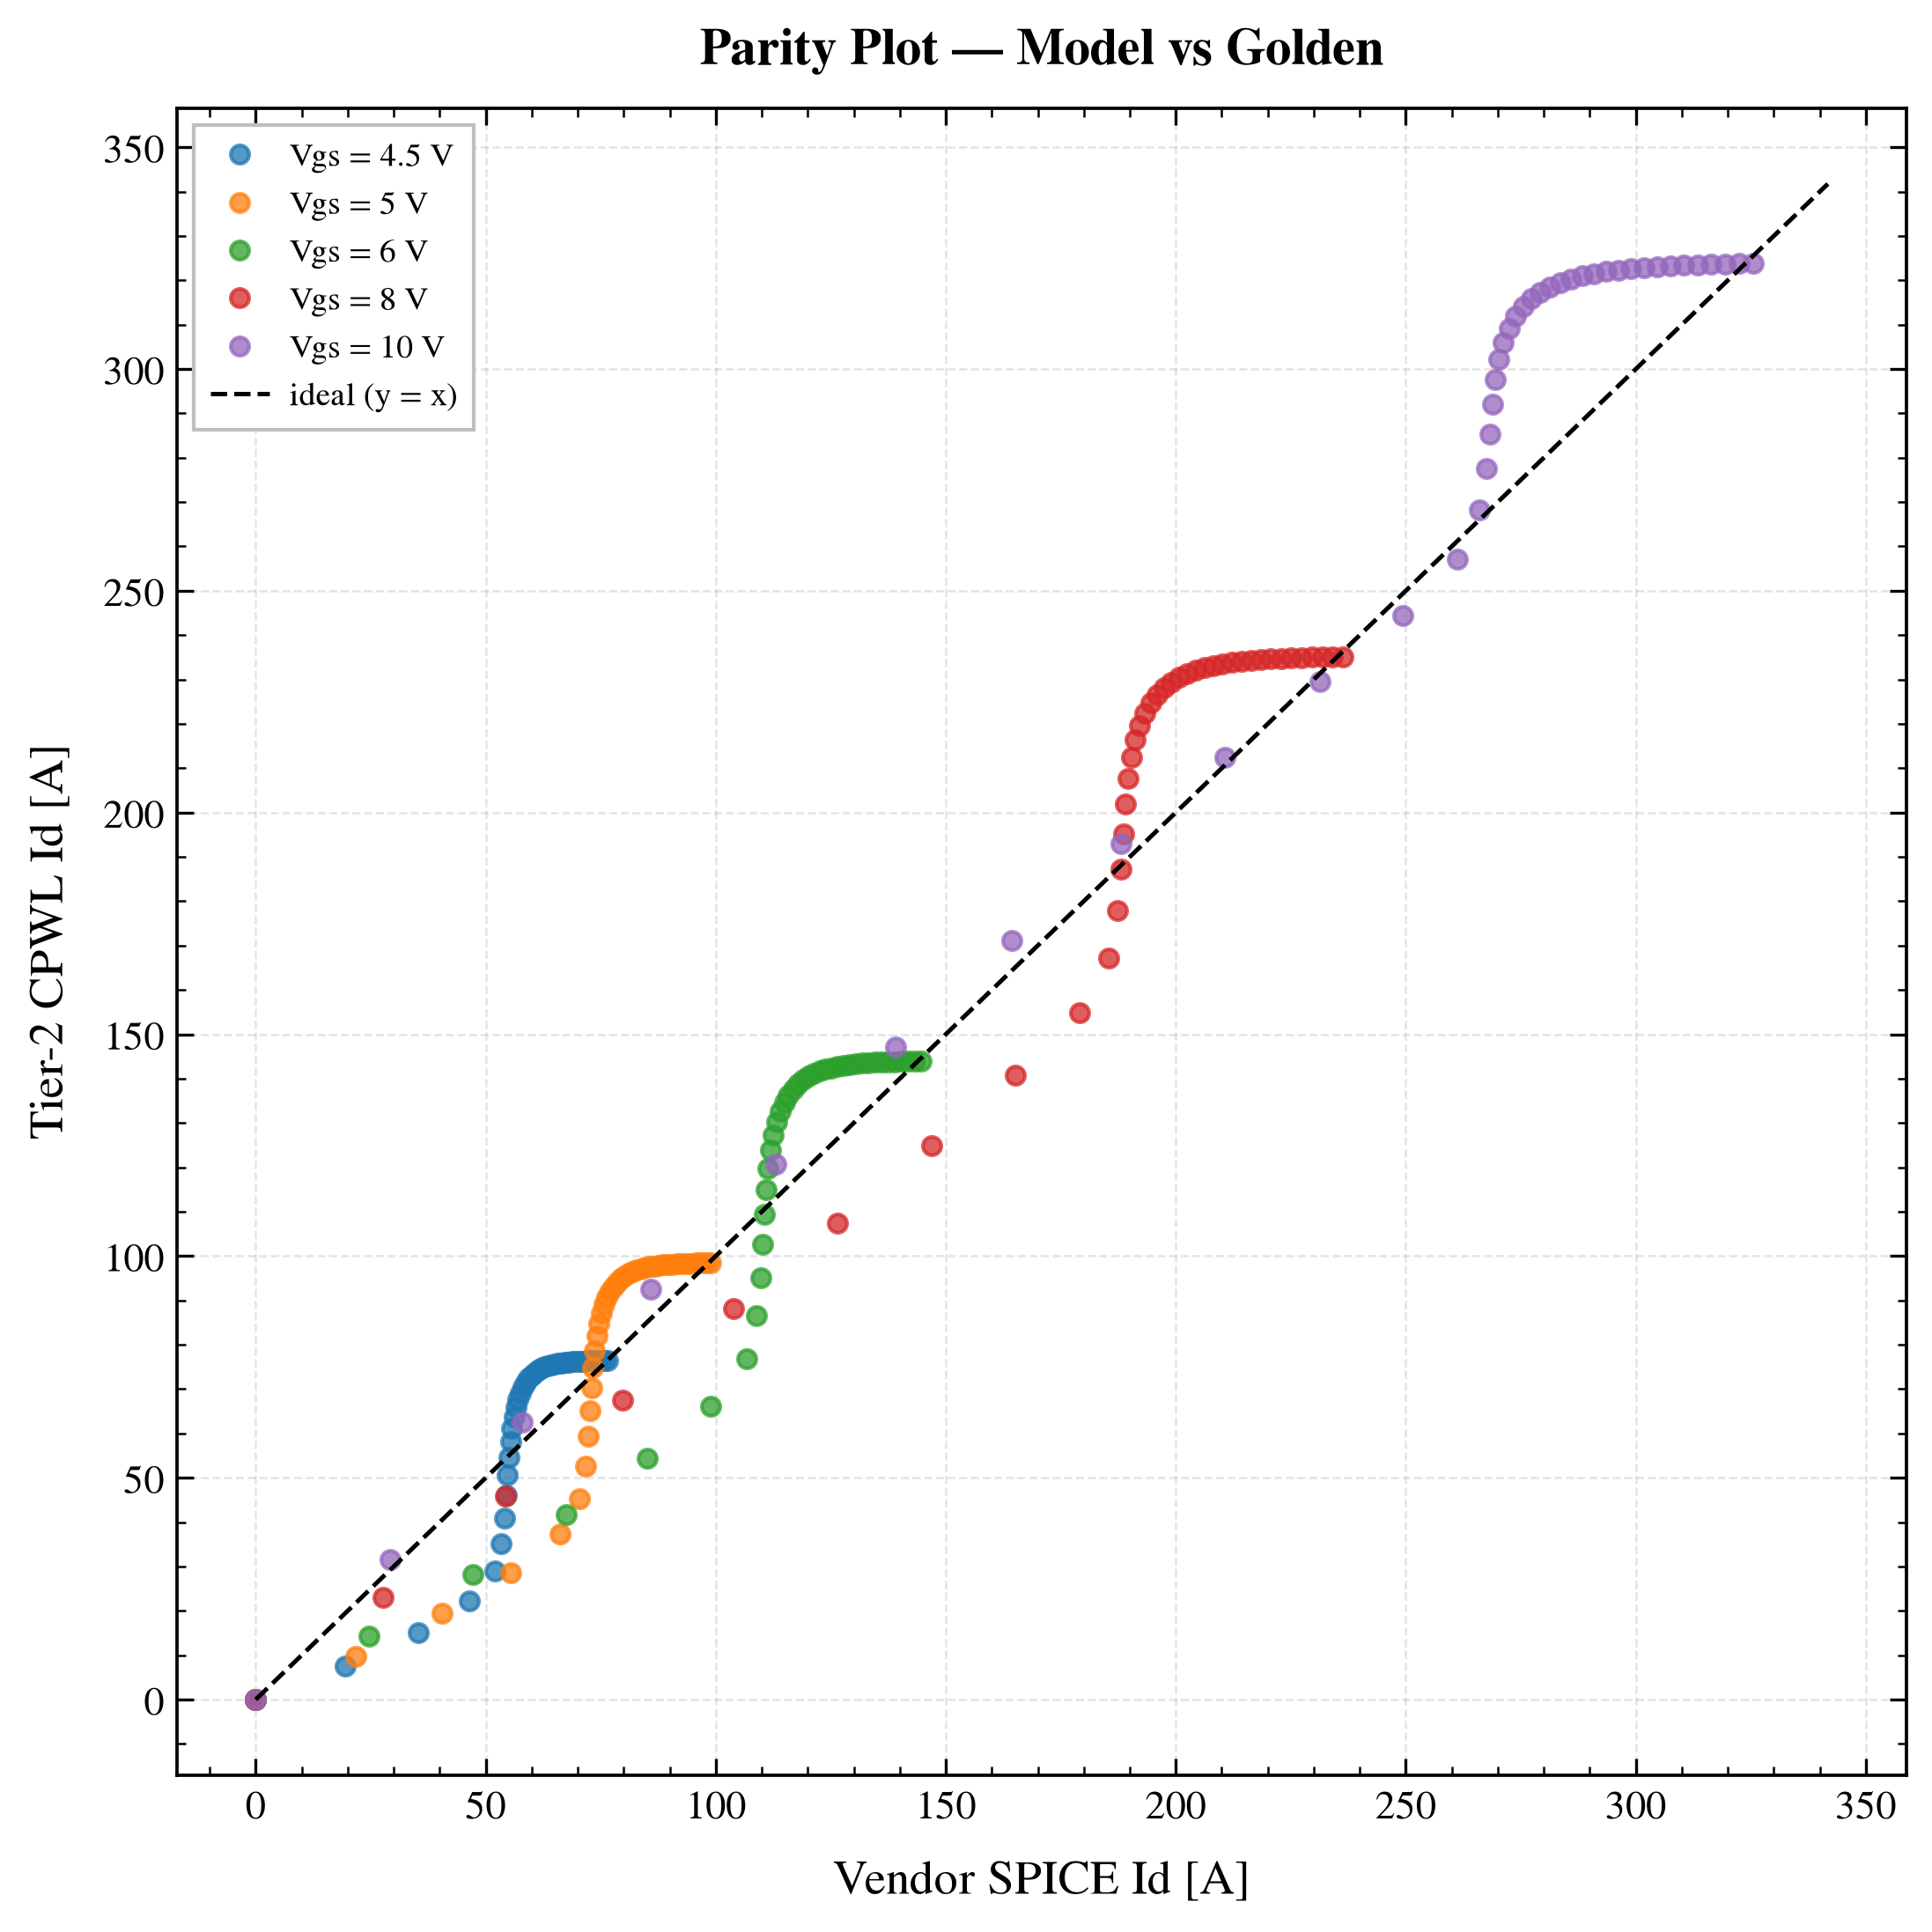

FAIL - worst curve Vgs = 4.5 V at 14.30%


In [11]:
# Comparison plot 4: parity scatter vs ideal line
fig_par = plot_parity(pairs)
plt.show()

verdict = "PASS - model within fidelity target" if report.all_passed \
    else f"FAIL - worst curve {report.worst.name} at " \
         f"{report.worst.rel_rmse_pct:.2f}%"
print(verdict)